<a href="https://colab.research.google.com/github/ramiro-ing/DL-breast-cancer/blob/version_final_entrega/Obligatorio_UNet_entrega_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Obligatorio - Taller de Deep Learning

**Fecha de entrega:** 8/12/2026 hasta las 21:00 (hora de Montevideo). Es también el cierre de la competencia en Kaggle (último envío).
**Puntaje máximo:** 50 puntos

**Integrantes:** Ramiro Rodríguez (145782), Ignacio Buscio (275945), Tania Almeida (191253)

## Obligatorio

El objetivo de este obligatorio es evaluar su conocimiento en Deep Learning mediante la implementación completa de un modelo de segmentación de imágenes basado en el paper [**"U-Net: Convolutional Networks for Biomedical Image Segmentation"**](https://arxiv.org/pdf/1505.04597). Toda la implementación debe realizarse desde cero utilizando PyTorch, y los estudiantes tendrán la libertad de ajustar ciertos hiperparámetros y configuraciones mientras mantengan la esencia del paper original.

La tarea de este año es la **segmentación de lesiones mamarias en imágenes de ecografía**: para cada imagen, el modelo debe indicar qué píxeles pertenecen a la lesión.

### **Competencia en Kaggle**

Además, como parte de este obligatorio, participarán en una competencia privada en Kaggle donde se les proporcionará un dataset de test oculto (sin target). Deberán subir sus predicciones a Kaggle y se evaluarán en función de la métrica **Dice Coefficient (Coeficiente de Dice)**. Esta competencia les permitirá comparar sus resultados con los de sus compañeros en un entorno real de evaluación.

Las imágenes de test **provienen de otros centros y fueron adquiridas con otros ecógrafos** que las imágenes de entrenamiento. Por lo tanto, un buen resultado en validación no garantiza un buen resultado en test: el modelo debe **generalizar a un dominio distinto** del que vio durante el entrenamiento.

### **¿Qué es el Dice Coefficient?**
El **Dice Coefficient**, también conocido como F1-score para segmentación, es una métrica utilizada para evaluar la similitud entre la predicción y la anotación manual en tareas de segmentación. Se define de la siguiente manera:

$$
\text{Dice} = \frac{2 \cdot |A \cap B|}{|A| + |B|}
$$

Donde:
- $A$ es el conjunto de píxeles predichos como pertenecientes a la clase positiva.
- $B$ es el conjunto de píxeles verdaderos pertenecientes a la clase positiva.
- $|A \cap B|$ es la intersección de $A$ y $B$, es decir, los píxeles correctamente predichos como positivos.

Un valor de Dice de **1** indica una predicción perfecta, mientras que un valor de **0** indica que no hay coincidencia entre la predicción y el valor verdadero. En la competencia, el Dice se calcula **por imagen** y luego se promedia sobre las imágenes de test. Todas las imágenes de test contienen una lesión, por lo que **la predicción de cada imagen debe tener al menos un píxel de lesión**: si alguna fila tiene la máscara vacía, Kaggle rechaza el envío completo. Para aprobar el obligatorio es necesario obtener un puntaje de al menos **0.65** en la tabla pública de Kaggle.

### **Criterios a Evaluar**

1. **Análisis del Dataset (5 puntos):**
   - Exploración y visualización del dataset para comprender su estructura y características (tamaños de imagen, proporción de píxeles de lesión, pacientes, equipos de adquisición, etc.).
   - Comparación entre los equipos de adquisición del conjunto de entrenamiento, e identificación de las diferencias que pueden afectar al modelo cuando se aplique a imágenes de otros equipos.
   - Justificación de las decisiones tomadas en el preprocesamiento de datos, como el tamaño de entrada del modelo, la normalización, el aumento de datos (data augmentation) y la partición del dataset en conjuntos de entrenamiento y validación.

2. **Implementación Correcta del Modelo U-Net (20 puntos):**
   - Construcción de la arquitectura U-Net siguiendo la estructura descrita en el paper, permitiendo ajustes como el número de filtros, funciones de activación y métodos de inicialización de pesos.
   - Se aceptan mejoras, por ejemplo batch normalization u otras funciones de activación.

3. **Entrenamiento del Modelo (10 puntos):**
   - Configuración adecuada del ciclo de entrenamiento, incluyendo la elección de la función de pérdida y del optimizador (Adam, SGD, etc.).
   - Uso de técnicas de regularización para mejorar la generalización del modelo, como el dropout, batch normalization y data augmentation.
   - Gráficas y análisis de la evolución del entrenamiento, mostrando las curvas de pérdida y métricas relevantes tanto en el conjunto de entrenamiento como en el de validación.
   - Puede utilizarse experimentación con hiperparámetros con Weights & Biases (W&B) para optimizar el rendimiento del modelo. Este punto es opcional, pero se valorará positivamente si se justifica su uso y se presentan resultados claros.

4. **Evaluación de Resultados (10 puntos):**
   - Evaluación exhaustiva del modelo utilizando métricas de segmentación como **Dice Coefficient**.
   - Análisis detallado de los resultados, incluyendo un análisis de errores para identificar y discutir casos difíciles.
   - Análisis del efecto del cambio de dominio: qué tipo de imágenes o lesiones se segmentan peor y por qué.
   - Visualización de ejemplos representativos de segmentaciones correctas e incorrectas, comparando con las etiquetas manuales proporcionadas en el dataset.

5. **Participación y Resultados en la Competencia Kaggle (5 puntos):**
   - Participación activa en la competencia de Kaggle, con al menos un (1) envío de predicciones.
   - Puntaje obtenido en la tabla de posiciones de Kaggle, evaluado en base al **Dice Coefficient** en el conjunto de test oculto. Es necesario obtener al menos **0.65** en la tabla pública para aprobar el obligatorio.

   Notas:
   - **Cualquier decisión debe ser justificada en el notebook.**
   - El **Dice Coefficient** es la métrica utilizada para evaluar el desempeño de los modelos de segmentación en esta competencia.

### **Run-Length Encoding (RLE)**

Dado que no se suben las imágenes segmentadas directamente a Kaggle, se requiere usar **Run-Length Encoding (RLE)** para comprimir las máscaras de predicción en una cadena de texto que será evaluada. El **RLE** es una técnica de compresión donde se representan secuencias consecutivas de píxeles en formato `start length`, indicando la posición de inicio y la longitud de cada secuencia de píxeles positivos.

Para calcular el **RLE**, se sigue el siguiente proceso:

1. Se aplanan las máscaras predichas en un solo vector (por columnas, orden Fortran). La máscara es un array de numpy de forma `(alto, ancho)` con valores 0 y 1.
2. Se identifican los píxeles con valor positivo (1) y se calculan las secuencias consecutivas.
3. Se registra la posición de inicio de cada secuencia (comenzando en 1) y su longitud en formato `start length`.

Este formato comprimido se sube a Kaggle en lugar de las imágenes segmentadas.

**Importante:** no se aceptan máscaras vacías (ver la sección anterior). Las imágenes de test tienen tamaños distintos. La máscara de cada imagen debe codificarse **con el tamaño original de esa imagen**. Si el modelo trabaja con otro tamaño, la predicción debe llevarse de vuelta al tamaño original antes de calcular el RLE.

#### **Ejemplo de RLE**

```python
import numpy as np

def rle_encode(mask):
    pixels = np.array(mask).flatten(order='F')  # Aplanar la máscara en orden Fortran
    pixels = np.concatenate([[0], pixels, [0]])  # Añadir ceros al principio y final
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1  # Encontrar transiciones
    runs[1::2] = runs[1::2] - runs[::2]  # Calcular longitudes
    return ' '.join(str(x) for x in runs)

mask = np.array([[0, 0, 1, 0, 0],
                 [0, 1, 1, 1, 0],
                 [1, 1, 1, 0, 0],
                 [0, 0, 0, 1, 1]])

print(rle_encode(mask))
```

> **Salida:** 3 1 6 2 9 3 14 1 16 1 20 1


### **Sobre el Dataset**

El dataset contiene imágenes de ecografía mamaria en escala de grises, cada una con una lesión (benigna o maligna) segmentada manualmente por especialistas.

- **Entrenamiento** (`train/`): imágenes (`train/images/`) y máscaras binarias (`train/masks/`, con el mismo nombre de archivo que la imagen; 255 = lesión, 0 = fondo). El archivo `train/train.csv` indica, para cada imagen, el paciente (`case`), el equipo de adquisición (`device`) y la patología (`pathology`). Un mismo paciente puede tener más de una imagen: los sufijos `-l` y `-r` del nombre corresponden a dos vistas de la misma lesión, y `-s` a una vista única.
- **Test** (`test/images/`): imágenes sin máscara, de otros centros y otros equipos. Cada imagen de test contiene al menos una lesión. **Las imágenes de test se usan únicamente para generar las predicciones que se envían a Kaggle**: no pueden usarse para entrenar, ajustar ni analizar el modelo.
- Las imágenes se entregan **en su resolución original**, que varía de una imagen a otra. La elección del tamaño de entrada del modelo es parte del trabajo.
- `sample_submission.csv` muestra el formato de la entrega: una fila por imagen de test, con las columnas `id` y `encoded_pixels` (cada fila contiene un único píxel, solo como ejemplo del formato).

### **Reglas de la Competencia**

- **Solo se pueden usar los datos de entrenamiento provistos.** No se permite usar datos externos (incluidas las versiones originales de los datasets citados en la sección *Datos y Atribución*) ni modelos o pesos pre-entrenados: la U-Net se entrena desde cero.
- Cada equipo puede realizar como máximo **dos (2) envíos por día** y debe seleccionar **dos (2)** envíos para la evaluación final.
- La tabla pública se calcula con el 80 % de las imágenes de test y es la que se usa para la aprobación. La posición final se define con el 20 % restante (tabla privada), que se revela al cierre de la competencia.
- **Premio:** el equipo en el primer puesto de la tabla privada recibe un ejemplar del libro [*The Welch Labs Illustrated Guide to AI*](https://www.welchlabs.com/ai-book), siempre que apruebe la defensa del obligatorio respondiendo correctamente al menos cuatro (4) de las cinco (5) preguntas.

### **Instrucciones de Entrega**

- Deberán entregar un Jupyter Notebook (.ipynb) que contenga todo el código y las explicaciones necesarias para ejecutar la implementación, el entrenamiento y la evaluación del modelo.
- **El notebook principal no puede superar las 50 páginas una vez exportado a PDF** (con sus salidas: tablas, gráficas e imágenes). Se corrige el notebook principal; lo que exceda ese límite no se tiene en cuenta.
- Opcionalmente, pueden entregar **notebooks secundarios** con material de apoyo. Por ejemplo, `experimentos_augmentation.ipynb` con todos los entrenamientos de una búsqueda de hiperparámetros: el notebook principal incluye solo la tabla de resultados y las conclusiones, y referencia al secundario para el detalle. Los notebooks secundarios no son obligatorios.
- El notebook debe incluir secciones bien documentadas explicando las decisiones de diseño del modelo, los experimentos realizados, y los resultados obtenidos.
- El código debe estar escrito de manera clara.
- La entrega debe realizarse a través de la plataforma de gestión de ORT (gestion.ort.edu.uy) antes de la fecha límite.

### **Materiales Adicionales**

Para facilitar su trabajo, pueden consultar los siguientes recursos:

- [U-Net: Convolutional Networks for Biomedical Image Segmentation (paper original)](https://arxiv.org/abs/1505.04597)
- [Documentación de PyTorch](https://pytorch.org/docs/stable/index.html)
- [Tutoriales y recursos adicionales en Kaggle](https://www.kaggle.com/)
- [Convolución Transpuesta](https://d2l.ai/chapter_computer-vision/transposed-conv.html)

### **Datos y Atribución**

- **Entrenamiento:** dataset BUS-BRA (ver la licencia en `train/LICENSE.txt`).

  > Gómez-Flores, W., Gregorio-Calas, M. J., & Coelho de Albuquerque Pereira, W. (2024). BUS-BRA: A breast ultrasound dataset for assessing computer-aided diagnosis systems. *Medical Physics*, 51(4), 3110–3123. https://doi.org/10.1002/mp.16812

- **Test:** dataset Breast-Lesions-USG, licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Las imágenes de test fueron modificadas y renombradas para la competencia, y se descartaron los casos sin lesión.

  > Pawłowska, A., Ćwierz-Pieńkowska, A., Domalik, A., Jaguś, D., Kasprzak, P., Matkowski, R., Fura, Ł., Nowicki, A., & Zolek, N. (2024). A Curated Benchmark Dataset for Ultrasound Based Breast Lesion Analysis (Breast-Lesions-USG) (Version 1) [dataset]. The Cancer Imaging Archive. https://doi.org/10.7937/9WKK-Q141

  > Pawłowska, A., et al. (2024). A curated benchmark dataset for ultrasound based breast lesion analysis. *Scientific Data*, 11, 148. https://doi.org/10.1038/s41597-024-02984-z

Ambos datasets son públicos. Usar sus máscaras originales (o cualquier otra anotación externa) para generar o corregir predicciones viola las reglas de la competencia.

### **Enlace a la Competencia**

La competencia abre el **miércoles 7 de octubre de 2026**. Es privada: para unirse, cada integrante debe ingresar con su cuenta de Kaggle al [enlace de invitación](https://www.kaggle.com/t/c6463c3f3c4c45918b447ebd582c5f5f). Luego, la competencia queda disponible en [kaggle.com/competitions/tdl-obligatorio-2026](https://www.kaggle.com/competitions/tdl-obligatorio-2026).

## Introducción a esta implementación

Este notebook implementa desde cero, en PyTorch, una U-Net para segmentar lesiones mamarias en imágenes de ecografía, siguiendo el paper de Ronneberger, Fischer y Brox (2015). Para cada imagen el modelo devuelve un mapa del mismo tamaño que indica qué píxeles pertenecen a la lesión, y el desempeño se mide con el coeficiente de Dice por imagen, promediado sobre el conjunto evaluado, que es la métrica de la competencia de Kaggle tdl-obligatorio-2026. Para aprobar se requiere un Dice de al menos 0.65 en la tabla pública.

El recorrido sigue el orden de la letra. Primero se accede a los datos, desde Google Drive o subiéndolos desde la computadora, y se analiza el dataset, con énfasis en las diferencias entre los equipos de adquisición, porque el test proviene de otros ecógrafos. Luego se justifica el preprocesamiento y la partición, se implementa la U-Net, se definen la función de pérdida y la métrica, se entrenan cuatro experimentos y se comparan, se construye un ensamble de tres particiones con la mejor configuración, se evalúa en detalle el modelo final, con un análisis de errores y del efecto del cambio de dominio, y finalmente se generan las predicciones para Kaggle.

La implementación conserva la esencia del paper: un camino de contracción con convoluciones 3×3, ReLU y max-pooling que duplica los canales en cada nivel, un camino de expansión con convoluciones transpuestas que los reduce a la mitad, conexiones de salto que concatenan los mapas del encoder con los del decoder, una convolución 1×1 final, inicialización de pesos con desvío √(2/N), data augmentation para compensar la escasez de datos y una pérdida que da más peso a los píxeles de borde. Se aparta del paper en el uso de padding en las convoluciones, la incorporación de batch normalization, la cantidad de filtros, la pérdida BCE + Dice con una salida sigmoide en lugar de softmax con entropía cruzada, el optimizador AdamW y la ausencia de deformaciones elásticas. Cada una de estas decisiones se justifica en la sección correspondiente. Un cuarto experimento evalúa un preprocesamiento orientado al cambio de dominio, que conserva la relación de aspecto, normaliza cada imagen por separado y agrega augmentation de intensidad, y las predicciones finales se limpian conservando solo la componente conexa más grande.

Las celdas de instalación, imports, semilla, dispositivo, exploración visual y análisis de resoluciones provienen del notebook base de la Tarea 1.

### Uso de IA generativa

Se utilizó Claude como apoyo para modelar la arquitectura y buscar posibles transformaciones de data augmentation. El equipo revisó cada aporte y es responsable del contenido final.

In [ ]:
!pip install -q torchinfo wandb

import glob
import os
import random
import shutil
import sys
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import wandb
from google.colab import drive, files
from IPython.display import Markdown, display
from PIL import Image
from scipy import ndimage
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import Dataset, DataLoader, Subset
from torchinfo import summary
from torchvision import tv_tensors
from torchvision.transforms import InterpolationMode
from torchvision.transforms import v2 as T

### Acceso a los datos


In [ ]:
USE_DRIVE = True        # False: subir tdl-obligatorio-2026.zip y utils.py desde la computadora
DRIVE_DIR = Path("/content/drive/MyDrive/TDL_obligatorio")         # carpeta de Drive con utils.py y el zip
ZIP_NAMES = ["tdl-obligatorio-2026.zip", "tdl-obligatorio_2026.zip"]
CONTENT = Path("/content")
DATA_ZIP = None
sys.path.insert(0, str(CONTENT))

if (CONTENT / "utils.py").exists() and (CONTENT / "train").exists() and (CONTENT / "test").exists():
    print("utils.py y el dataset ya están en el entorno: se omite la carga y la descompresión.")
else:
    if USE_DRIVE:
        try:
            drive.mount("/content/drive")
            zips = [DRIVE_DIR / n for n in ZIP_NAMES if (DRIVE_DIR / n).exists()]
            if not zips:
                zips = [p for n in ZIP_NAMES for p in Path("/content/drive/MyDrive").rglob(n)]
            if zips and (zips[0].parent / "utils.py").exists():
                DATA_ZIP = zips[0]
                shutil.copy(DATA_ZIP.parent / "utils.py", CONTENT / "utils.py")
                print(f"Desde Drive: {DATA_ZIP} y utils.py")
            else:
                print("No se encontraron el zip y utils.py en Drive: se piden desde la computadora.")
        except Exception as e:
            print(f"No se pudo usar Drive ({type(e).__name__}): se piden desde la computadora.")

    if DATA_ZIP is None:
        print("Seleccionar tdl-obligatorio-2026.zip y utils.py:")
        for name in files.upload():
            if name.endswith(".zip"):
                DATA_ZIP = CONTENT / name
            elif name.endswith(".py") and name.startswith("utils") and name != "utils.py":
                shutil.move(CONTENT / name, CONTENT / "utils.py")
        assert DATA_ZIP is not None, "Falta subir el zip del dataset"
    assert (CONTENT / "utils.py").exists(), "Falta utils.py"

    local_zip = CONTENT / DATA_ZIP.name
    if DATA_ZIP != local_zip:
        shutil.copy(DATA_ZIP, local_zip)
    print(f"Descomprimiendo {local_zip.name}...")
    with zipfile.ZipFile(local_zip, "r") as zip_ref:
        zip_ref.extractall(CONTENT)
    print(f"¡{local_zip.name} descomprimido con éxito!")

Mounted at /content/drive
Desde Drive: /content/drive/MyDrive/Maestria_IA/Taller de deeplearning/Obligatorio/tdl-obligatorio-2026.zip y utils.py
Descomprimiendo tdl-obligatorio-2026.zip...
¡tdl-obligatorio-2026.zip descomprimido con éxito!


Se fija la semilla para reproducibilidad

In [ ]:
SEED = 23

torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

In [ ]:
from utils import train, get_device

DEVICE = get_device()
print(f"Usando {DEVICE}")

Usando cuda


### Configuración de ejecución y Weights & Biases

La variable USE_WANDB controla si las corridas se registran en Weights & Biases, donde quedan las curvas por época, la configuración y las métricas finales de cada experimento. Con el valor False el notebook funciona igual sin registrar nada, y la función wandb_safe envuelve cada llamada a wandb para que un fallo de red o de credenciales nunca detenga el entrenamiento. Weights & Biases se utilizó en los experimentos iniciales del trabajo para registrar y comparar las primeras corridas; luego se dejó USE_WANDB en False para dedicar el tiempo de GPU disponible a los experimentos principales de la sección 6.

NUM_WORKERS se fija en 0 porque el dataset completo se carga en memoria y las transformaciones son baratas, por lo que los batches se cargaron en el proceso principal, lo que evitó los bloqueos que a veces producen los procesos hijos del DataLoader en Colab. La variable HARDWARE registra la GPU utilizada para documentar las condiciones de cada corrida. El entrenamiento requiere un entorno de ejecución con GPU.

In [ ]:
USE_WANDB = False    # True: registrar las corridas en wandb (pide la API key)

NUM_WORKERS = 0
HARDWARE = f"GPU CUDA ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else DEVICE.upper()

WANDB_ENTITY = None   # None: usa la cuenta del usuario logueado en wandb
WANDB_PROJECT = "tdl_obligatorio_unet"
WANDB_MODE = "online" if USE_WANDB else "disabled"
if WANDB_MODE == "online":
    try:
        wandb.login()
    except Exception as e:
        print(f"No se pudo iniciar sesión en wandb ({e}). Se usa modo offline.")
        WANDB_MODE = "offline"

def wandb_safe(fn):
    try:
        return fn()
    except Exception as e:
        print(f"(wandb: {type(e).__name__}: {e}) se ignora")

print(f"Hardware: {HARDWARE} | wandb en modo: {WANDB_MODE} | workers: {NUM_WORKERS}")

Hardware: GPU CUDA (Tesla T4) | wandb en modo: disabled | workers: 0


## 1. Datos

La celda siguiente arma las listas ordenadas de rutas de imágenes y máscaras de entrenamiento y de imágenes de test, e imprime cuántas hay de cada una, lo que permite comprobar que haya la misma cantidad de imágenes que de máscaras.

La métrica de la competencia es el coeficiente de Dice, calculado para cada imagen a partir del conjunto $A$ de píxeles predichos como lesión y el conjunto $B$ de píxeles de lesión de la máscara manual, y promediado sobre las $M$ imágenes evaluadas:

$$\text{Dice}(A, B) = \frac{2\,|A \cap B|}{|A| + |B|}, \qquad \text{Score} = \frac{1}{M} \sum_{m=1}^{M} \text{Dice}(A_m, B_m).$$

In [ ]:
BASE_PATH = Path("/content")
TRAIN_IMAGES_PATH = BASE_PATH / "train" / "images"
TRAIN_MASKS_PATH = BASE_PATH / "train" / "masks"
TEST_IMAGES_PATH = BASE_PATH / "test" / "images"

train_images = sorted(glob.glob(str(TRAIN_IMAGES_PATH / "*.*")))
train_masks = sorted(glob.glob(str(TRAIN_MASKS_PATH / "*.*")))
test_images = sorted(glob.glob(str(TEST_IMAGES_PATH / "*.*")))

print(f"Imágenes de entrenamiento encontradas: {len(train_images)}")
print(f"Máscaras de entrenamiento encontradas: {len(train_masks)}")
print(f"Imágenes de prueba encontradas: {len(test_images)}")

Imágenes de entrenamiento encontradas: 1875
Máscaras de entrenamiento encontradas: 1875
Imágenes de prueba encontradas: 252


### Exploración visual del dataset

Se muestran tres ejemplos aleatorios de entrenamiento, cada uno con su máscara, y tres imágenes de test, que no tienen máscara. Las ecografías son imágenes en escala de grises con ruido speckle, en las que la lesión aparece como una región más oscura (hipoecoica) de bordes a veces difusos. Las máscaras son binarias, con valor 255 en la lesión y 0 en el fondo, y cada imagen contiene una única lesión. Las dos celdas siguientes analizan la resolución de las imágenes de entrenamiento y de test.

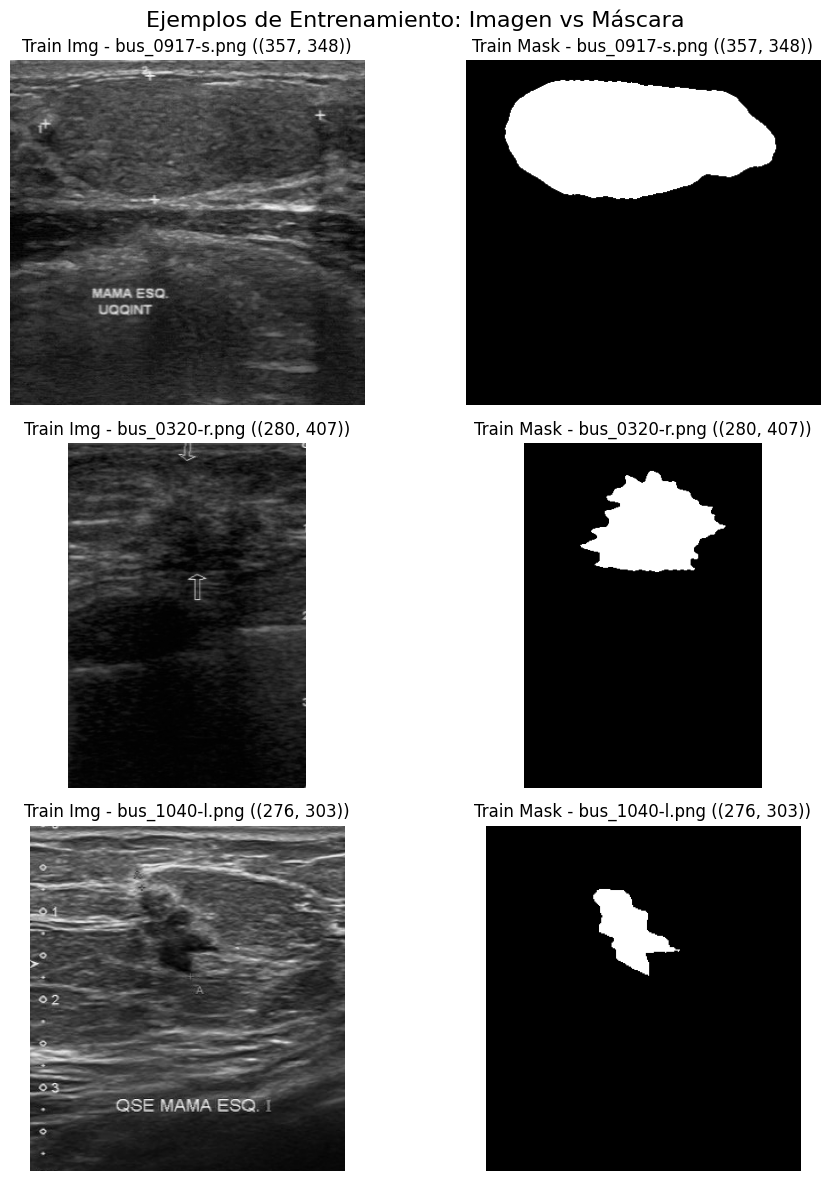

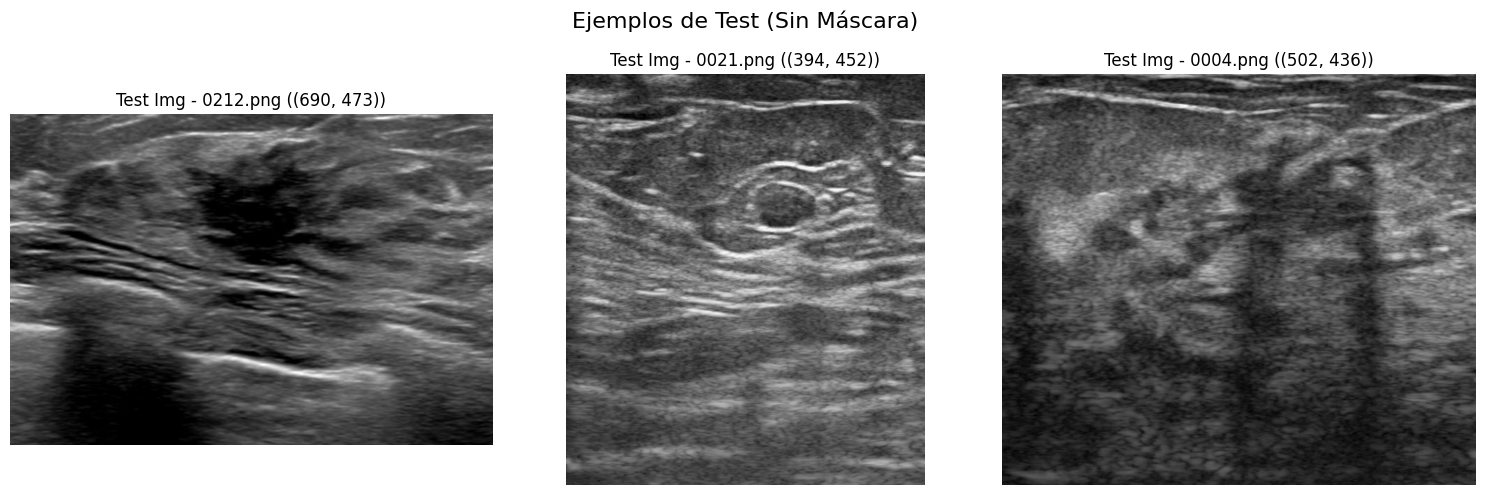

In [ ]:
random.seed(SEED)
num_samples = 3
train_indices = random.sample(range(len(train_images)), num_samples)
test_indices = random.sample(range(len(test_images)), num_samples)

fig, axes = plt.subplots(num_samples, 2, figsize=(10, num_samples * 4))
plt.suptitle("Ejemplos de Entrenamiento: Imagen vs Máscara", fontsize=16)
for i, idx in enumerate(train_indices):
    img = Image.open(train_images[idx]).convert("L")
    mask = Image.open(train_masks[idx]).convert("L")

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"Train Img - {Path(train_images[idx]).name} ({img.size})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"Train Mask - {Path(train_masks[idx]).name} ({mask.size})")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))
plt.suptitle("Ejemplos de Test (Sin Máscara)", fontsize=16)
for i, idx in enumerate(test_indices):
    img = Image.open(test_images[idx]).convert("L")
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Test Img - {Path(test_images[idx]).name} ({img.size})")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
def analyze_resolutions(image_paths, dataset_name):
    widths = []
    heights = []

    for path in image_paths:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)

    widths = np.array(widths)
    heights = np.array(heights)

    print(f"=== Análisis de Resoluciones: {dataset_name} ===")
    print(f"Total de imágenes: {len(image_paths)}")
    print(f"Ancho (Width):  Min={widths.min()}, Max={widths.max()}, Promedio={widths.mean():.1f}, Mediana={np.median(widths)}")
    print(f"Alto (Height):  Min={heights.min()}, Max={heights.max()}, Promedio={heights.mean():.1f}, Mediana={np.median(heights)}")

    resolutions = [f"{w}x{h}" for w, h in zip(widths, heights)]
    most_common = Counter(resolutions).most_common(5)
    print("Resoluciones más comunes:")
    for res, count in most_common:
        print(f"  - {res}: {count} imágenes ({count/len(image_paths)*100:.1f}%)")
    print("\n")

analyze_resolutions(train_images, "Entrenamiento (Train)")
analyze_resolutions(test_images, "Prueba (Test)")

=== Análisis de Resoluciones: Entrenamiento (Train) ===
Total de imágenes: 1875
Ancho (Width):  Min=240, Max=579, Promedio=321.3, Mediana=286.0
Alto (Height):  Min=268, Max=478, Promedio=391.3, Mediana=383.0
Resoluciones más comunes:
  - 276x305: 29 imágenes (1.5%)
  - 276x304: 26 imágenes (1.4%)
  - 276x369: 21 imágenes (1.1%)
  - 322x434: 20 imágenes (1.1%)
  - 323x433: 20 imágenes (1.1%)


=== Análisis de Resoluciones: Prueba (Test) ===
Total de imágenes: 252
Ancho (Width):  Min=353, Max=967, Promedio=558.0, Mediana=494.5
Alto (Height):  Min=251, Max=609, Promedio=473.4, Mediana=471.5
Resoluciones más comunes:
  - 423x450: 1 imágenes (0.4%)
  - 666x492: 1 imágenes (0.4%)
  - 436x510: 1 imágenes (0.4%)
  - 566x444: 1 imágenes (0.4%)
  - 502x436: 1 imágenes (0.4%)




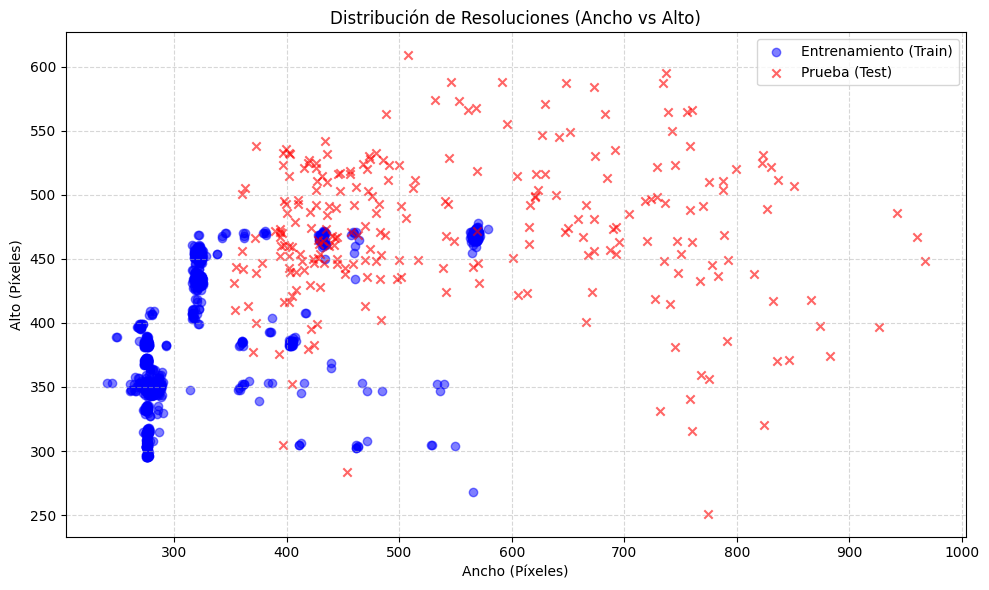

In [ ]:
def get_dimensions(image_paths):
    widths = []
    heights = []
    for path in image_paths:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
    return widths, heights

train_w, train_h = get_dimensions(train_images)
test_w, test_h = get_dimensions(test_images)

plt.figure(figsize=(10, 6))
plt.scatter(train_w, train_h, alpha=0.5, label='Entrenamiento (Train)', color='blue')
plt.scatter(test_w, test_h, alpha=0.6, label='Prueba (Test)', color='red', marker='x')

plt.title('Distribución de Resoluciones (Ancho vs Alto)')
plt.xlabel('Ancho (Píxeles)')
plt.ylabel('Alto (Píxeles)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Las resoluciones de entrenamiento y de test difieren de manera notoria. En entrenamiento el ancho va de 240 a 579 píxeles, con mediana 286, y el alto de 268 a 478, con mediana 383, por lo que las imágenes suelen ser más altas que anchas. En test el ancho va de 353 a 967 píxeles, con mediana 494.5, y el alto de 251 a 609, con mediana 471.5: las imágenes son más grandes y en general más anchas que altas, y prácticamente no se repite ninguna resolución. Esto anticipa dos decisiones del preprocesamiento. Todas las imágenes deben llevarse a un tamaño fijo para entrenar en batches, y las predicciones de test deben volver al tamaño original de cada imagen antes de codificarlas en RLE. Además, como el redimensionado a un cuadrado deforma las imágenes en proporciones distintas en train y en test, el modelo verá en test lesiones con otra relación de aspecto, lo que justifica incluir variaciones de escala y encuadre en el data augmentation.

## 2. Metadatos del dataset

El archivo train/train.csv indica, para cada imagen de entrenamiento, el paciente (case), el equipo de adquisición (device) y la patología (pathology). La celda une esa información con las rutas ya obtenidas, usando el nombre del archivo sin extensión como clave, y arma la tabla df con una fila por imagen. Esa tabla es la base del análisis exploratorio, de la partición por paciente y del análisis por equipo. La celda verifica además que cada imagen del CSV tenga su archivo de imagen y su máscara, y carga sample_submission.csv, que define el orden y los identificadores de las 252 imágenes de test.

In [ ]:
TRAIN_DIR = BASE_PATH / "train"
df = pd.read_csv(TRAIN_DIR / "train.csv")
sub = pd.read_csv(next(BASE_PATH.rglob("sample_submission.csv")))

ID_COL = next(c for c in df.columns if c not in ("case", "device", "pathology"))
df["stem"] = df[ID_COL].astype(str).map(lambda s: Path(s).stem)

img_files = {Path(p).stem: p for p in train_images}
mask_files = {Path(p).stem: p for p in train_masks}
df["img_path"] = df["stem"].map(img_files)
df["mask_path"] = df["stem"].map(mask_files)
assert df["img_path"].notna().all() and df["mask_path"].notna().all(), "faltan imágenes o máscaras"

print(f"Train: {len(df)} imágenes | Test: {len(sub)} imágenes (sin máscara)")
df.head()

Train: 1875 imágenes | Test: 252 imágenes (sin máscara)


,id,case,device,pathology,stem,img_path,mask_path
0,bus_0001-l.png,1,GE Logiq 7 @10-14MHz,malignant,bus_0001-l,/content/train/images/bus_0001-l.png,/content/train/masks/bus_0001-l.png
1,bus_0001-r.png,1,GE Logiq 7 @10-14MHz,malignant,bus_0001-r,/content/train/images/bus_0001-r.png,/content/train/masks/bus_0001-r.png
2,bus_0002-l.png,2,GE Logiq 7 @10-14MHz,benign,bus_0002-l,/content/train/images/bus_0002-l.png,/content/train/masks/bus_0002-l.png
3,bus_0002-r.png,2,GE Logiq 7 @10-14MHz,benign,bus_0002-r,/content/train/images/bus_0002-r.png,/content/train/masks/bus_0002-r.png
4,bus_0003-l.png,3,GE Logiq 7 @10-14MHz,malignant,bus_0003-l,/content/train/images/bus_0003-l.png,/content/train/masks/bus_0003-l.png


## 3. Análisis exploratorio de datos

El análisis busca responder tres preguntas: cuántos pacientes, equipos y patologías hay y si existe desbalance, qué tamaño tienen las imágenes y qué fracción de la imagen ocupa la lesión, y en qué se diferencian los equipos de adquisición en brillo, contraste y resolución. La última pregunta es central, porque el test proviene de otros centros y otros ecógrafos, y las diferencias que se observen entre los equipos de entrenamiento dan una idea del tipo de cambio de dominio que el modelo enfrentará.

### 3.1 Composición: pacientes, equipos y patologías

La celda cuenta las imágenes y los pacientes, cruza equipo con patología y grafica la cantidad de imágenes por equipo y por patología.

**1875 imágenes de 1064 pacientes** (≈1.76 imágenes por paciente).

pathology,benign,malignant,All
device,,,
GE Logiq 5 @10-12MHz,566,243,809
GE Logiq 7 @10-14MHz,617,285,902
Toshiba Aplio 300 @12-14 MHz,71,68,139
U-Systems @10-14MHz,14,11,25
All,1268,607,1875


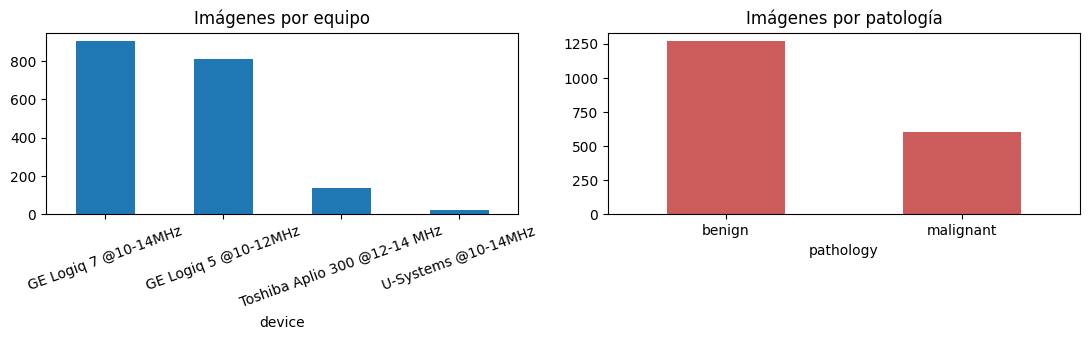

In [ ]:
n_cases = df["case"].nunique()
display(Markdown(f"**{len(df)} imágenes de {n_cases} pacientes** (≈{len(df) / n_cases:.2f} imágenes por paciente)."))

display(pd.crosstab(df["device"], df["pathology"], margins=True))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["device"].value_counts().plot(kind="bar", ax=axes[0], title="Imágenes por equipo", rot=20)
df["pathology"].value_counts().plot(kind="bar", ax=axes[1], title="Imágenes por patología", rot=0, color="indianred")
plt.tight_layout()
plt.show()

El conjunto de entrenamiento tiene 1875 imágenes de 1064 pacientes. De ellos, 811 aportan dos vistas de la misma lesión (sufijos -l y -r) y 253 una vista única (sufijo -s), lo que da en promedio 1.76 imágenes por paciente. Esta estructura obliga a partir los datos por paciente y no por imagen, porque dos vistas de la misma lesión son muy parecidas y repartirlas entre train y validación inflaría la métrica de validación.

Hay cuatro equipos y la distribución es muy desbalanceada. GE Logiq 7 aporta 902 imágenes y GE Logiq 5 aporta 809, mientras que Toshiba Aplio 300 aporta solo 139 y U-Systems apenas 25. En cuanto a la patología, 1268 imágenes (67.6 %) corresponden a lesiones benignas y 607 (32.4 %) a malignas. El desbalance entre equipos implica que el modelo aprenderá sobre todo la apariencia de los dos equipos GE, y que la partición debe estratificarse por equipo para que los equipos minoritarios estén representados en validación.

### 3.2 Tamaños, proporción de lesión y brillo

La celda recorre una sola vez todas las imágenes y máscaras para medir la resolución original, la fracción de píxeles de lesión y el brillo medio y el desvío de intensidad de cada imagen, que se usa como medida de contraste. Estos valores se agregan como columnas de df y se grafican: la resolución por equipo, el histograma del porcentaje de lesión y la fracción de lesión por equipo.


Ancho: 240-579 px (mediana 286) | Alto: 268-478 px (mediana 383)
Lesión: mediana 6.2% de la imagen (p5 = 1.5%, p95 = 22.5%)


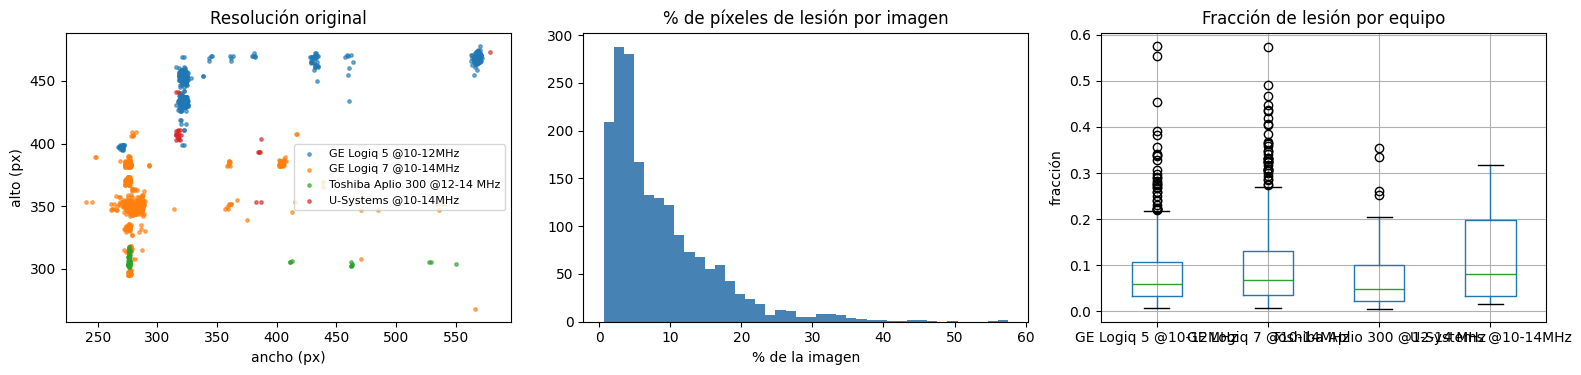

In [ ]:
rows = []
for ip, mp in zip(df["img_path"], df["mask_path"]):
    with Image.open(ip) as im:
        w, h = im.size
        a = np.array(im.convert("L"), dtype=np.float32)
    with Image.open(mp) as mm:
        m = np.array(mm.convert("L")) > 127
    rows.append((w, h, m.mean(), a.mean(), a.std()))

stat_cols = ["width", "height", "lesion_frac", "mean_int", "std_int"]
df[stat_cols] = pd.DataFrame(rows, columns=stat_cols, index=df.index)

print(f"Ancho: {df.width.min():.0f}-{df.width.max():.0f} px (mediana {df.width.median():.0f}) | "
      f"Alto: {df.height.min():.0f}-{df.height.max():.0f} px (mediana {df.height.median():.0f})")
print(f"Lesión: mediana {100 * df.lesion_frac.median():.1f}% de la imagen "
      f"(p5 = {100 * df.lesion_frac.quantile(.05):.1f}%, p95 = {100 * df.lesion_frac.quantile(.95):.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for dev, g in df.groupby("device"):
    axes[0].scatter(g.width, g.height, s=6, label=dev, alpha=.6)
axes[0].set(title="Resolución original", xlabel="ancho (px)", ylabel="alto (px)")
axes[0].legend(fontsize=8)
axes[1].hist(100 * df.lesion_frac, bins=40, color="steelblue")
axes[1].set(title="% de píxeles de lesión por imagen", xlabel="% de la imagen")
df.boxplot(column="lesion_frac", by="device", ax=axes[2])
axes[2].set(title="Fracción de lesión por equipo", xlabel="", ylabel="fracción")
plt.suptitle("")
plt.tight_layout()
plt.show()

La lesión ocupa en mediana el 6.2 % de la imagen, con un percentil 5 de 1.5 % y un percentil 95 de 22.5 %, y en total el 8.7 % de los píxeles son de lesión. Existe por lo tanto un fuerte desbalance entre fondo y lesión, y hay lesiones muy chicas. Una pérdida puramente por píxel como la entropía cruzada puede alcanzar valores bajos prediciendo casi todo fondo, lo que motiva combinarla con la pérdida Dice, que mide el solapamiento de la lesión independientemente de la cantidad de fondo. Las lesiones malignas son más grandes que las benignas, con una mediana de 10.2 % frente a 4.6 %, de modo que las lesiones benignas pequeñas serán probablemente las más difíciles. Los gráficos muestran también que cada equipo forma un grupo propio de resoluciones.

### 3.3 Comparación entre equipos de adquisición

La celda resume, para cada equipo, la cantidad de imágenes y pacientes, la resolución mediana, el porcentaje mediano de lesión, el brillo medio y el contraste medio, y grafica la distribución del brillo y del contraste por equipo.

,imagenes,pacientes,ancho_mediano,alto_mediano,lesion_pct_mediana,brillo_medio,contraste_medio
device,,,,,,,
GE Logiq 5 @10-12MHz,809,490,323.0,448.0,5.9,104.599998,49.799999
GE Logiq 7 @10-14MHz,902,488,276.0,352.0,6.7,66.900002,30.700001
Toshiba Aplio 300 @12-14 MHz,139,72,276.0,305.0,4.8,72.000000,39.099998
U-Systems @10-14MHz,25,14,317.0,407.0,8.1,35.299999,34.799999


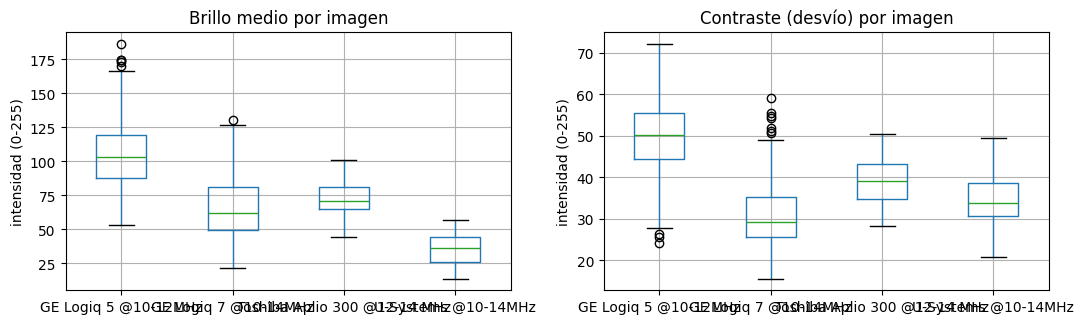

In [ ]:
dev_table = df.groupby("device").agg(
    imagenes=("stem", "size"),
    pacientes=("case", "nunique"),
    ancho_mediano=("width", "median"),
    alto_mediano=("height", "median"),
    lesion_pct_mediana=("lesion_frac", lambda s: 100 * s.median()),
    brillo_medio=("mean_int", "mean"),
    contraste_medio=("std_int", "mean"),
)
display(dev_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df.boxplot(column="mean_int", by="device", ax=axes[0])
axes[0].set(title="Brillo medio por imagen", xlabel="", ylabel="intensidad (0-255)")
df.boxplot(column="std_int", by="device", ax=axes[1])
axes[1].set(title="Contraste (desvío) por imagen", xlabel="", ylabel="intensidad (0-255)")
plt.suptitle("")
plt.tight_layout()
plt.show()

Los equipos difieren sobre todo en la intensidad de la imagen. GE Logiq 5 produce las imágenes más claras y contrastadas, con un brillo medio de 104.6 y un desvío de 49.8 en la escala de 0 a 255. GE Logiq 7 y Toshiba Aplio 300 son más oscuros, con brillos de 66.9 y 72.0 y desvíos de 30.7 y 39.1, y U-Systems es el más oscuro, con un brillo medio de 35.3. También cambia la resolución mediana: 323×448 píxeles en GE Logiq 5, 276×352 en GE Logiq 7, 276×305 en Toshiba y 317×407 en U-Systems. La fracción de lesión es en cambio parecida entre equipos, con medianas entre 4.8 % y 8.1 %, de modo que la tarea es la misma y lo que cambia es la apariencia.

Estas diferencias explican el riesgo ante el cambio de dominio: una red entrenada mayoritariamente con imágenes GE (91 % del dataset) puede asociar la lesión a un rango de intensidades, contraste o relación de aspecto propios de esos equipos, y perder desempeño cuando esos parámetros cambian en los ecógrafos de test.

## 4. Preprocesamiento y partición train / validación

### 4.1 Partición

La partición se hace por paciente, usando la columna case como grupo, para que las dos vistas de una misma lesión queden siempre del mismo lado. Si se partiera por imagen, el modelo podría ver en entrenamiento una vista casi idéntica a la que luego se evalúa en validación, y la métrica resultaría optimista. Además se estratifica por equipo, para que cada equipo aparezca en validación en la misma proporción que en entrenamiento. Ambas condiciones se cumplen con StratifiedGroupKFold de scikit-learn con 7 pliegues, del cual se toma un pliegue, aproximadamente el 14 % de los datos, como validación.

La función split_cases recibe un conjunto de índices de df y devuelve los índices de train y de validación. El argumento fold elige cuál de los 7 pliegues se usa como validación. La partición principal es el pliegue 0, y los pliegues 1 y 2 se usan en el ensamble de la sección 6.5. Como StratifiedGroupKFold reparte los pacientes en pliegues disjuntos, las validaciones de distintos pliegues no comparten pacientes. La celda comprueba que ningún paciente quede en ambos conjuntos y muestra la proporción de cada equipo en train y en validación. Con la semilla fijada, la partición deja 1605 imágenes para entrenamiento y 270 para validación, con proporciones por equipo prácticamente iguales.

In [ ]:
def split_cases(idx, n_splits=7, fold=0):
    subset = df.iloc[idx]
    train_pos, val_pos = list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED).split(subset, subset["device"], subset["case"]))[fold]
    return idx[train_pos], idx[val_pos]

tr_idx, va_idx = split_cases(np.arange(len(df)))

train_patients = set(df.iloc[tr_idx]["case"])
val_patients = set(df.iloc[va_idx]["case"])
assert len(train_patients & val_patients) == 0, "hay pacientes en train y val"
print(f"Train: {len(tr_idx)} imágenes | Val: {len(va_idx)} imágenes")
pd.DataFrame({"train": df.iloc[tr_idx]["device"].value_counts(normalize=True),
              "val": df.iloc[va_idx]["device"].value_counts(normalize=True)}).round(3)

Train: 1605 imágenes | Val: 270 imágenes


,train,val
device,,
GE Logiq 7 @10-14MHz,0.480,0.485
GE Logiq 5 @10-12MHz,0.431,0.437
Toshiba Aplio 300 @12-14 MHz,0.075,0.067
U-Systems @10-14MHz,0.014,0.011


### 4.2 Tamaño de entrada y carga en memoria

Las imágenes se llevan a 320×320 píxeles y a un único canal de escala de grises. Este tamaño es un compromiso entre conservar el detalle del borde de la lesión, que se pierde con resoluciones más bajas, y poder entrenar varias corridas en un tiempo razonable en una GPU T4. Es además divisible por 2⁴, lo que permite aplicar cuatro max-pooling 2×2 sin restos y llegar a mapas de 20×20 en el cuello de botella. En una primera etapa se intentó trabajar con imágenes de 512×512 junto con la configuración de canales del paper, que llega a 1024 canales en el cuello de botella, pero la memoria de la GPU de Colab no alcanzó para entrenar con esa combinación, ya que la memoria que ocupan las activaciones crece con el cuadrado del lado de la imagen y con la cantidad de canales de cada nivel. Por eso se redujeron tanto el tamaño de entrada como la cantidad de filtros (sección 5). El paper, en cambio, trabaja con teselas de 572×572 y convoluciones sin padding que producen una salida de 388×388, y recompone imágenes grandes con la estrategia overlap-tile. En este trabajo, como las ecografías miden entre 240 y 579 píxeles de lado, se redimensionó la imagen completa.

La diferencia se explica por el tamaño de salida de una convolución con núcleo $k$, padding $p$ y stride 1, que es $n_{out} = n_{in} + 2p - k + 1$. En el paper $k = 3$ y $p = 0$, de modo que cada convolución quita 2 píxeles ($n_{out} = n_{in} - 2$) y, sumando las 18 convoluciones 3×3 de los distintos niveles, una entrada de 572 píxeles termina en una salida de 388. Aquí $k = 3$ y $p = 1$, por lo que $n_{out} = n_{in}$ en todas las convoluciones, y solo los max-pooling cambian la resolución, $n \to n/2$, hasta $320 / 2^4 = 20$ píxeles en el cuello de botella.

Las imágenes se redimensionan con interpolación bilineal (para suavizar las transiciones de gris) y las máscaras con interpolación nearest (para no introducir valores intermedios entre 0 y 1). Para el experimento 4 se prepara además una segunda versión en memoria, X_pad e Y_pad, mediante la función pad_square: dado que las imágenes de entrenamiento son más altas que anchas y las de test más anchas que altas, estirar directamente a 320×320 deforma las lesiones en sentidos opuestos. pad_square evita esta distorsión rellenando con negro (0) hasta un cuadrado de lado $s = \max(w, h)$ antes de redimensionar a 320×320, y al predecir en test ese relleno se recorta antes de volver al tamaño original.

In [ ]:
IMG_SIZE = 320

def pad_square(im):
    w, h = im.size
    side = max(w, h)
    off_x, off_y = (side - w) // 2, (side - h) // 2
    canvas = Image.new("L", (side, side), 0)
    canvas.paste(im, (off_x, off_y))
    return canvas, (off_x, off_y, side)

def read_resized(path, resample, pad=False):
    with Image.open(path) as im:
        im = im.convert("L")
        if pad:
            im = pad_square(im)[0]
        return torch.from_numpy(np.array(im.resize((IMG_SIZE, IMG_SIZE), resample)))

X = torch.stack([read_resized(p, Image.BILINEAR) for p in df["img_path"]]).unsqueeze(1)
Y = (torch.stack([read_resized(p, Image.NEAREST) for p in df["mask_path"]]).unsqueeze(1) > 127).to(torch.uint8)
X_pad = torch.stack([read_resized(p, Image.BILINEAR, pad=True) for p in df["img_path"]]).unsqueeze(1)
Y_pad = (torch.stack([read_resized(p, Image.NEAREST, pad=True) for p in df["mask_path"]]).unsqueeze(1) > 127).to(torch.uint8)
print(f"X {tuple(X.shape)} {X.dtype} | Y {tuple(Y.shape)} {Y.dtype} | píxeles de lesión: {Y.float().mean():.1%} (base), "
      f"{Y_pad.float().mean():.1%} (con relleno)")

X (1875, 1, 320, 320) torch.uint8 | Y (1875, 1, 320, 320) torch.uint8 | píxeles de lesión: 8.7% (base), 6.8% (con relleno)


### 4.3 Normalización y transformaciones

En el pipeline base, que usan los experimentos 1 a 3, la imagen se pasa a float en el rango [0, 1] y se normaliza con media 0.5 y desvío 0.5, lo que la lleva al rango [-1, 1]. Se usan constantes fijas en lugar de la media y el desvío de entrenamiento porque el test proviene de otros ecógrafos con otro brillo y contraste, como se vio en la sección 3.3, y una estadística calculada sobre los equipos de entrenamiento no representa mejor a esos equipos que un centrado fijo.

Si $I \in \{0, \dots, 255\}$ es la intensidad original de un píxel, la entrada al modelo es

$$x = \frac{I/255 - 0.5}{0.5} \in [-1, 1].$$

El paper subraya que el data augmentation es esencial cuando hay pocas imágenes anotadas, y utiliza desplazamientos, rotaciones, variaciones de intensidad y, sobre todo, deformaciones elásticas aleatorias. En este trabajo el conjunto de entrenamiento aplica cinco transformaciones antes de la normalización. RandomResizedCrop con escala entre 0.7 y 1.0 recorta y reescala la imagen, lo que simula distintos encuadres y tamaños de lesión y compensa en parte la diferencia de relación de aspecto entre train y test. RandomHorizontalFlip refleja la imagen con probabilidad 0.5, ya que una lesión espejada sigue siendo una lesión. RandomRotation de hasta 15 grados simula una leve inclinación del transductor. ColorJitter con contraste 0.4 y RandomAutocontrast con probabilidad 0.5 varían el contraste de la imagen, y cumplen el papel de las variaciones de intensidad del paper: dado que los equipos difieren sobre todo en brillo y contraste, estas transformaciones obligan al modelo a no depender del contraste propio de los equipos de entrenamiento.

No se usan deformaciones elásticas, que el paper presenta como la transformación clave en microscopía. En ecografía la forma de la lesión es en sí misma informativa, ya que las lesiones malignas suelen tener bordes irregulares y las benignas contornos más regulares, y deformarla de manera aleatoria podría alterar justamente esa señal. Por eso el grupo optó por transformaciones geométricas rígidas.

Con torchvision.transforms.v2, al pasar la imagen como tv_tensors.Image y la máscara como tv_tensors.Mask, las transformaciones geométricas se aplican con los mismos parámetros aleatorios a ambas, la máscara se interpola con nearest y las transformaciones de contraste y la normalización solo afectan a la imagen. La validación y el test solo reciben la normalización.

El experimento 4 usa una segunda versión del preprocesamiento, pensada para el cambio de equipo. La normalización fija se reemplaza por una normalización por imagen: cada imagen se lleva a media 0 y desvío 1 con su propia media $\mu$ y su propio desvío $\sigma$, calculados sobre los píxeles distintos de cero para que el relleno no los altere,

$$x = \frac{I/255 - \mu}{\sigma + \epsilon}.$$

Con esta normalización, una imagen globalmente más oscura o con menos contraste, como las de U-Systems (brillo medio 35.3) frente a las de GE Logiq 5 (104.6), llega al modelo con la misma escala.

In [ ]:
normalize = [T.ToDtype(torch.float32, scale=True), T.Normalize(mean=[0.5], std=[0.5])]

eval_transforms = T.Compose(normalize)

train_transforms_aug = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15, interpolation=InterpolationMode.BILINEAR),
    T.ColorJitter(contrast=0.4),
    T.RandomAutocontrast(p=0.5),
    *normalize,
])

def image_only(fn):
    return T.Lambda(lambda x: tv_tensors.wrap(fn(x), like=x), tv_tensors.Image)

def random_gamma(x, p=0.5, low=0.7, high=1.5):
    if torch.rand(1).item() < p:
        return T.functional.adjust_gamma(x, float(torch.empty(1).uniform_(low, high)))
    return x

def speckle(x, p=0.5, sigma=0.1):
    if torch.rand(1).item() < p:
        return (x * (1 + sigma * torch.randn_like(x))).clamp(0, 1)
    return x

def standardize(x):
    v = x[x > 0]
    v = v if v.numel() > 100 else x.flatten()
    return (x - v.mean()) / (v.std() + 1e-6)

normalize_v2 = [T.ToDtype(torch.float32, scale=True), image_only(standardize)]
eval_transforms_v2 = T.Compose(normalize_v2)

train_transforms_v2 = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15, interpolation=InterpolationMode.BILINEAR),
    image_only(random_gamma),
    T.RandomApply([T.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.3),
    T.ToDtype(torch.float32, scale=True),
    image_only(speckle),
    image_only(standardize),
])

#### Transformaciones

El data augmentation genera, a partir de cada imagen de entrenamiento, versiones distintas en cada época, de modo que el modelo nunca ve dos veces exactamente la misma imagen. El objetivo es aumentar la generalización: que el modelo aprenda lo que define a una lesión, su forma, su ecogenicidad y su contraste con el tejido vecino, y no detalles propios de las imágenes de entrenamiento, como su encuadre, su brillo o el equipo con el que fueron adquiridas. Esto importa en dos sentidos. Por un lado, con 1605 imágenes de entrenamiento una red de millones de parámetros puede memorizarlas, y el augmentation actúa como regularización, como señala el paper para el caso de pocas imágenes anotadas. Por otro, el test proviene de otros ecógrafos, y cada transformación simula una variación que el modelo puede encontrar en esas imágenes. Todas las transformaciones se aplican solo en entrenamiento. La validación y el test reciben únicamente la conversión a float y la normalización.

Las transformaciones geométricas se aplican con los mismos parámetros a la imagen y a la máscara, para que la máscara siga marcando la lesión. RandomResizedCrop recorta una región aleatoria que cubre entre el 70 % y el 100 % del área de la imagen, con una relación de aspecto entre 3/4 y 4/3, y la vuelve a llevar a 320×320. Simula distintos encuadres y tamaños de lesión, ya que el operador puede centrar la lesión de distintas maneras y con distinta profundidad. RandomHorizontalFlip refleja la imagen de izquierda a derecha con probabilidad 0.5. Una lesión reflejada sigue siendo una lesión plausible y la anatomía de la mama es aproximadamente simétrica en esa dirección. En cambio no se usa el reflejo vertical, porque en una ecografía la piel está siempre arriba y la profundidad crece hacia abajo, y una imagen invertida no aparece nunca en la práctica. RandomRotation gira la imagen un ángulo aleatorio de hasta 15 grados en cada sentido, con interpolación bilineal para la imagen y nearest para la máscara, y simula una leve inclinación del transductor. Ángulos mayores generarían imágenes poco realistas, con la piel inclinada.

Las transformaciones de intensidad cambian solo los valores de gris de la imagen y no la máscara. En el pipeline base, ColorJitter con contraste 0.4 multiplica el contraste por un factor aleatorio entre 0.6 y 1.4, alejando o acercando cada píxel del gris medio de la imagen, y RandomAutocontrast, con probabilidad 0.5, estira el histograma para que el píxel más oscuro quede en negro y el más claro en blanco. Ambas simulan los distintos ajustes de ganancia y rango dinámico de cada ecógrafo, que la sección 3.3 mostró como la principal diferencia entre equipos.

En el pipeline v2 esas dos transformaciones dejan de tener efecto, porque son cambios afines de la intensidad, de la forma $I \to aI + b$, y la normalización por imagen los elimina. Por eso se reemplazan por transformaciones que la normalización no deshace. La corrección gamma aleatoria eleva la intensidad normalizada a una potencia, $I \to 255\,(I/255)^{\gamma}$, con $\gamma$ entre 0.7 y 1.5 y probabilidad 0.5: con $\gamma < 1$ aclara los tonos oscuros y con $\gamma > 1$ los oscurece, sin mover el negro ni el blanco. Es un cambio no lineal del brillo, similar a las distintas curvas de compresión logarítmica que aplican los ecógrafos, y es la variación de brillo que sobrevive a la normalización. El desenfoque gaussiano, con probabilidad 0.3, promedia cada píxel con sus vecinos usando un núcleo de 5×5 con desvío entre 0.1 y 1.5 píxeles, y simula equipos de menor resolución o transductores de menor frecuencia, que producen imágenes menos nítidas. El ruido speckle multiplica cada píxel por $1 + 0.1\,n$, con $n$ normal estándar y probabilidad 0.5. Imita el ruido granular característico de la ecografía, producido por la interferencia de los ecos, cuya textura cambia de un equipo a otro, y evita que el modelo dependa de la textura exacta de los equipos de entrenamiento. Al ser multiplicativo, el ruido es mayor en las zonas brillantes y nulo en el relleno negro, como ocurre con el speckle real.

Las últimas operaciones preparan la entrada de la red. ToDtype convierte la imagen de enteros entre 0 y 255 a valores reales entre 0 y 1. En el pipeline base, Normalize resta 0.5 y divide por 0.5, lo que deja la imagen en [-1, 1]. En el pipeline v2, standardize resta la media y divide por el desvío de la propia imagen, calculados sobre los píxeles distintos de cero, de modo que todas las imágenes llegan con media 0 y desvío 1 sin importar el brillo y el contraste del equipo. En el código, cada una de estas operaciones propias se escribe como una función fn que recibe y devuelve la imagen, y la función image_only la envuelve en un T.Lambda que la aplica solo a la imagen y la vuelve a marcar como tv_tensors.Image, para que la máscara pase sin cambios y las transformaciones siguientes la sigan reconociendo como imagen.


### 4.4 BUSDataset

La clase BUSDataset guarda las referencias a los tensores X e Y ya cargados en memoria y aplica la transformación en cada llamada a \_\_getitem\_\_, de modo que el augmentation produce una versión distinta de la imagen cada vez que se la pide.

In [ ]:
class BUSDataset(Dataset):
    def __init__(self, X, Y, transform):
        self.X, self.Y, self.transform = X, Y, transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img, mask = self.transform(tv_tensors.Image(self.X[i]), tv_tensors.Mask(self.Y[i]))
        return img.as_subclass(torch.Tensor), mask.as_subclass(torch.Tensor).float()

ds_aug = BUSDataset(X, Y, train_transforms_aug)
ds_eval = BUSDataset(X, Y, eval_transforms)
ds_aug_v2 = BUSDataset(X_pad, Y_pad, train_transforms_v2)
ds_eval_v2 = BUSDataset(X_pad, Y_pad, eval_transforms_v2)

### 4.5 Verificación visual del data augmentation



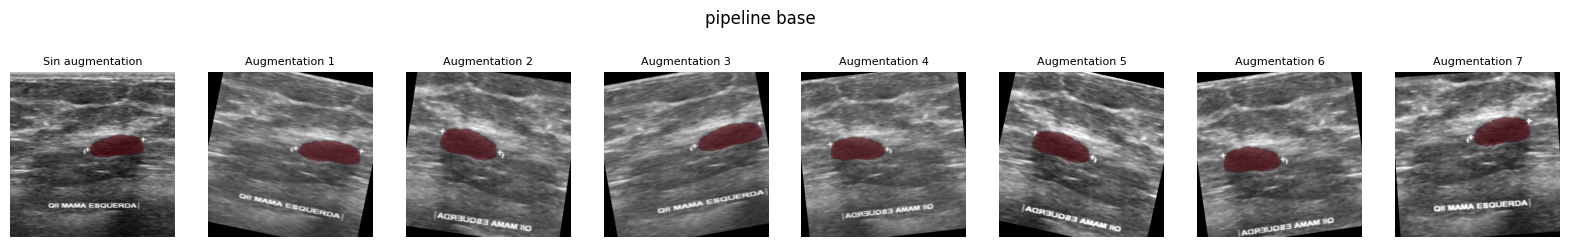

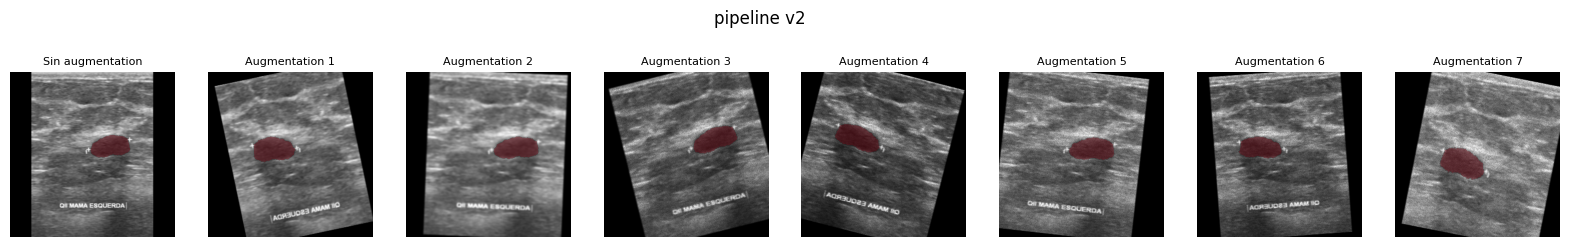

In [ ]:
def denorm(t):
    t = t.squeeze()
    return ((t - t.min()) / (t.max() - t.min() + 1e-8)).numpy()

def show_overlay(ax, img, mask, title=None):
    ax.imshow(img, cmap="gray")
    ax.imshow(np.ma.masked_equal((np.asarray(mask) > 0).astype(np.uint8), 0), cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis("off")

demo = int(tr_idx[0])
for ds_e, ds_a, nombre in [(ds_eval, ds_aug, "pipeline base"), (ds_eval_v2, ds_aug_v2, "pipeline v2")]:
    pairs = [ds_e[demo]] + [ds_a[demo] for _ in range(7)]
    fig, axes = plt.subplots(1, 8, figsize=(20, 3))
    for k, (ax, (img, mask)) in enumerate(zip(axes, pairs)):
        show_overlay(ax, denorm(img), mask.squeeze().numpy(), "Sin augmentation" if k == 0 else f"Augmentation {k}")
    fig.suptitle(nombre)
    plt.show()

### 4.6 DataLoaders

El batch size se fija en 16, porque una U-Net a 320×320 con los 64 ejemplos por batch del notebook base de la Tarea 1 no entra en la memoria de la GPU. El paper entrena con una sola imagen por batch y teselas grandes, y compensa con un momento de 0.99. Aquí un batch de 16 permite además que la batch normalization estime estadísticas estables.

La función get_loaders arma, para una partición dada, cuatro loaders. train_aug y train_noaug recorren las mismas imágenes de entrenamiento, mezcladas, con y sin augmentation. train_eval es una submuestra fija de 300 imágenes de entrenamiento sin augmentation que solo se usa para medir el Dice de train al final de cada época, y val recorre la validación sin augmentation y sin mezclar, de modo que su orden coincide con va_idx. La celda imprime la forma de un batch para comprobar que las imágenes llegan como float de forma (16, 1, 320, 320) y las máscaras con valores 0 y 1.

La función get_loaders recibe opcionalmente los datasets a usar. Con los datasets del pipeline v2 se arman los loaders_v2, que recorren exactamente las mismas imágenes de entrenamiento y de validación que los loaders base, de modo que la partición por paciente es la misma para los cuatro experimentos.

In [ ]:
BATCH_SIZE = 16

def make_loader(ds, idx, shuffle=False):
    return DataLoader(Subset(ds, list(idx)), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS)

def get_loaders(train_idx, val_idx, ds_train=None, ds_val=None):
    ds_train = ds_aug if ds_train is None else ds_train
    ds_val = ds_eval if ds_val is None else ds_val
    sample = np.random.RandomState(SEED).choice(train_idx, min(300, len(train_idx)), replace=False)
    return {"train_aug": make_loader(ds_train, train_idx, True), "train_noaug": make_loader(ds_val, train_idx, True),
            "train_eval": make_loader(ds_val, sample), "val": make_loader(ds_val, val_idx)}

loaders = get_loaders(tr_idx, va_idx)
loaders_v2 = get_loaders(tr_idx, va_idx, ds_aug_v2, ds_eval_v2)
x_b, y_b = next(iter(loaders["train_aug"]))
print(f"Batch de train: x {tuple(x_b.shape)} {x_b.dtype} | y {tuple(y_b.shape)} {y_b.dtype} | valores de y: {y_b.unique().tolist()}")

Batch de train: x (16, 1, 320, 320) torch.float32 | y (16, 1, 320, 320) torch.float32 | valores de y: [0.0, 1.0]


## 5. Modelo

La arquitectura respeta la estructura del paper. El camino de contracción aplica, en cada nivel, dos convoluciones 3×3 seguidas de ReLU y luego un max-pooling 2×2 con stride 2 que reduce la resolución a la mitad, mientras la cantidad de canales se duplica de un nivel al siguiente. En el fondo de la U hay un cuello de botella con otras dos convoluciones. El camino de expansión aplica en cada nivel una convolución transpuesta 2×2, que duplica la resolución y reduce los canales a la mitad, concatena el mapa del nivel correspondiente del encoder (la conexión de salto, que recupera la información espacial fina perdida en el pooling) y aplica otras dos convoluciones 3×3. Una convolución 1×1 final lleva los mapas de 32 canales a un único canal de salida por píxel.

Con $c_0 = $ base, el nivel $i$ del encoder tiene $c_i = c_0 \cdot 2^i$ canales, para $i = 0, \dots, 4$. La convolución transpuesta con núcleo $k = 2$ y stride $s = 2$ produce una salida de tamaño $n_{out} = (n_{in} - 1)\,s + k = 2\,n_{in}$, de modo que deshace exactamente el max-pooling del nivel correspondiente, y la concatenación con el mapa del encoder da $2 c_i$ canales, que el bloque de expansión vuelve a llevar a $c_i$.

La implementación es modular. La función conv_block construye el bloque de dos convoluciones y la clase UNet arma todos los niveles con listas de módulos (ModuleList) a partir de los canales base·2^i. Con base=64 y depth=4 se obtiene exactamente la configuración del paper, de 64 a 1024 canales. Cambiar base o depth ajusta el tamaño del modelo sin modificar el código. En forward, el encoder guarda la salida de cada bloque antes del pooling, y el decoder la recorre en orden inverso junto con las convoluciones transpuestas y los bloques de expansión.

Respecto del paper hay cinco diferencias. Las convoluciones usan padding=1, de modo que la salida tiene el mismo tamaño que la entrada y los mapas del encoder se concatenan sin recortarlos. El paper usa convoluciones sin padding, recorta los mapas antes de concatenarlos y por eso necesita la estrategia overlap-tile. Después de cada convolución se aplica batch normalization, que no existía cuando se publicó el paper y que la letra acepta como mejora. Estabiliza el entrenamiento desde cero y permite tasas de aprendizaje más altas. Las convoluciones que la preceden no usan sesgo, porque la batch normalization ya incluye un desplazamiento aprendido que lo vuelve redundante. Se usa base=32 en lugar de 64, lo que da 32 a 512 canales y unos 7.8 millones de parámetros en lugar de 31 millones, porque con 1605 imágenes de entrenamiento y sin pesos pre-entrenados un modelo más chico alcanza y entrena bastante más rápido. Además, la configuración del paper, con 1024 canales en el cuello de botella, no entró en la memoria de la GPU de Colab cuando se probó con imágenes de 512×512, como se mencionó en la sección 4.2: con base=64 cada mapa de activación tiene el doble de canales en todos los niveles, y la memoria necesaria para guardar las activaciones del batch durante el backpropagation supera la disponible. La salida es un único logit por píxel en lugar de dos canales con softmax, lo que para dos clases es equivalente. La sigmoide se aplica dentro de la pérdida y al predecir.

La equivalencia entre ambas salidas se ve al escribir la softmax de dos clases con logits $z_1$ (lesión) y $z_0$ (fondo):

$$p(\text{lesión}) = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0),$$

por lo que un único logit $z = z_1 - z_0$ con la sigmoide $\sigma(z) = 1 / (1 + e^{-z})$ es equivalente a la salida de dos canales. Por último, el paper menciona capas de dropout al final del camino de contracción, que aquí se implementan con Dropout2d en el cuello de botella para respetar la arquitectura original. En los experimentos se fija dropout=0 porque el modelo tiene cuatro veces menos parámetros que el del paper (7.8M frente a 31M), incorpora BatchNorm2d en todas las convoluciones —cuya variación por mini-batch ya actúa como regularizador y suele interferir con el dropout— y emplea data augmentation; las curvas del experimento 1 confirman que la brecha entre entrenamiento y validación es de apenas 0.03.

La inicialización de pesos sí coincide con el paper: los pesos de las convoluciones se inicializan con una normal de desvío √(2/N), donde N es la cantidad de entradas de cada neurona, que es la inicialización de Kaiming para ReLU, y los sesgos en cero.

Para una convolución con núcleo $k \times k$ y $c_{in}$ canales de entrada,

$$w \sim \mathcal{N}\!\left(0, \frac{2}{N}\right), \qquad N = k^2\, c_{in},$$

que para una convolución 3×3 sobre 64 canales da $N = 9 \cdot 64 = 576$, el mismo ejemplo que da el paper. El factor 2 compensa que la ReLU anula la mitad de las activaciones, y mantiene la varianza de las activaciones aproximadamente constante de una capa a la siguiente. La salida de summary de torchinfo muestra, capa por capa, la forma de los mapas de activación y la cantidad de parámetros.

In [ ]:
def conv_block(cin, cout, use_bn=True):
    layers = []
    for c in (cin, cout):
        layers += [nn.Conv2d(c, cout, 3, padding=1, bias=not use_bn),
                   nn.BatchNorm2d(cout) if use_bn else nn.Identity(),
                   nn.ReLU(inplace=True)]
    return nn.Sequential(*layers)

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32, depth=4, use_bn=True, dropout=0.0):
        super().__init__()
        channels = [base * 2 ** i for i in range(depth + 1)]
        self.enc = nn.ModuleList([conv_block(i, o, use_bn) for i, o in zip([in_ch] + channels[:-1], channels)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(channels[i + 1], channels[i], 2, stride=2) for i in range(depth)])
        self.dec = nn.ModuleList([conv_block(2 * channels[i], channels[i], use_bn) for i in range(depth)])
        self.pool, self.drop = nn.MaxPool2d(2), nn.Dropout2d(dropout)
        self.head = nn.Conv2d(channels[0], out_ch, 1)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for block in self.enc[:-1]:
            x = block(x)
            skips.append(x)
            x = self.pool(x)
        x = self.drop(self.enc[-1](x))
        for up, block, skip in zip(reversed(self.up), reversed(self.dec), reversed(skips)):
            x = block(torch.cat([skip, up(x)], dim=1))
        return self.head(x)

BASE = 32
summary(UNet(base=BASE), input_size=(BATCH_SIZE, 1, IMG_SIZE, IMG_SIZE))

Layer (type:depth-idx)                   Output Shape              Param #
UNet                                     [16, 1, 320, 320]         --
├─ModuleList: 1-9                        --                        (recursive)
│    └─Sequential: 2-1                   [16, 32, 320, 320]        --
│    │    └─Conv2d: 3-1                  [16, 32, 320, 320]        288
│    │    └─BatchNorm2d: 3-2             [16, 32, 320, 320]        64
│    │    └─ReLU: 3-3                    [16, 32, 320, 320]        --
│    │    └─Conv2d: 3-4                  [16, 32, 320, 320]        9,216
│    │    └─BatchNorm2d: 3-5             [16, 32, 320, 320]        64
│    │    └─ReLU: 3-6                    [16, 32, 320, 320]        --
├─MaxPool2d: 1-2                         [16, 32, 160, 160]        --
├─ModuleList: 1-9                        --                        (recursive)
│    └─Sequential: 2-2                   [16, 64, 160, 160]        --
│    │    └─Conv2d: 3-7                  [16, 64, 160, 160]    

### 5.1 Diagrama 3D de la arquitectura

La figura muestra la U-Net implementada como una secuencia de prismas en tres dimensiones, en el estilo de las figuras de arquitecturas convolucionales. Cada prisma representa un mapa de activación: su ancho crece con la cantidad de canales y su alto y profundidad con la resolución espacial, ambos en escala logarítmica para que los mapas de 20×20 sigan siendo visibles junto a los de 320×320. La U se forma porque cada nivel de profundidad se dibuja más abajo que el anterior. Los colores distinguen la entrada, los bloques de dos convoluciones del encoder, los max-pooling, el cuello de botella, las convoluciones transpuestas, los bloques del decoder y la convolución 1×1 de salida, y las líneas punteadas son las conexiones de salto: en cada nivel del decoder el prisma azul junto al naranja es el mapa copiado del encoder que se concatena con el resultado de la convolución transpuesta. Las etiquetas indican la resolución y la cantidad de canales de cada nivel. La figura reproduce la de la arquitectura del paper con los valores de esta implementación (entrada 320×320×1, canales de 32 a 512 y salida del mismo tamaño que la entrada gracias al padding).

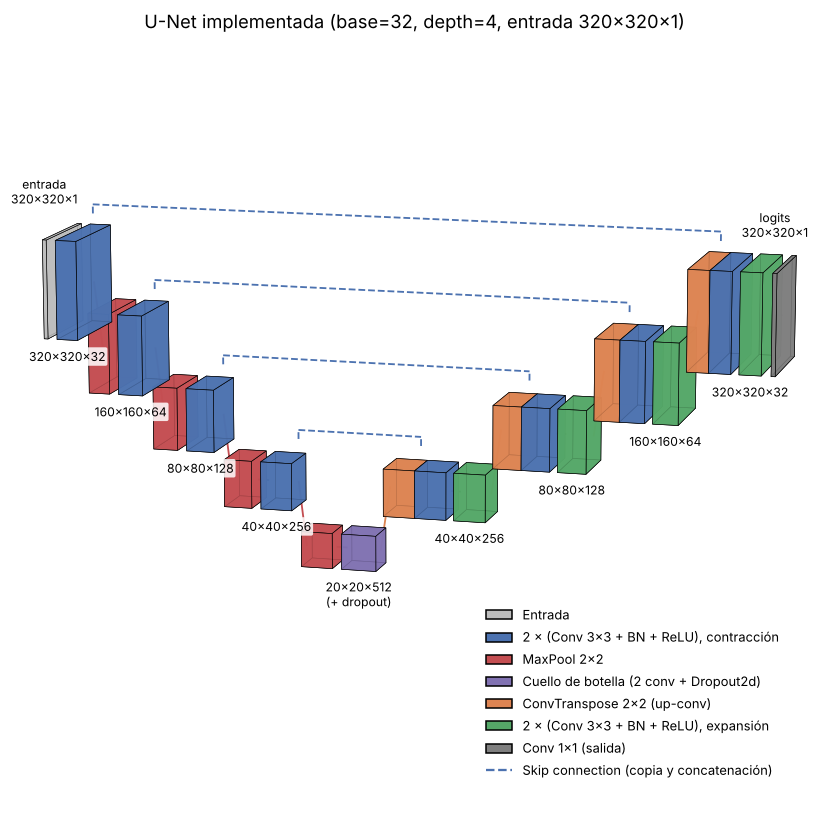

### 5.2 Función de pérdida: BCE + Dice

El paper entrena con una softmax por píxel combinada con entropía cruzada, ponderada por un mapa de pesos que compensa la frecuencia de cada clase y da mucho más peso a los bordes que separan células que se tocan.

En el paper la energía es

$$E = -\sum_{x \in \Omega} w(x) \log p_{\ell(x)}(x), \qquad w(x) = w_c(x) + w_0 \exp\!\left(-\frac{(d_1(x) + d_2(x))^2}{2\sigma^2}\right),$$

donde $p_{\ell(x)}(x)$ es la probabilidad softmax de la clase correcta del píxel $x$, $w_c$ equilibra la frecuencia de las clases y $d_1$, $d_2$ son las distancias a la primera y la segunda célula más cercanas. Aquí la pérdida es la suma de dos términos. El primero es la entropía cruzada binaria sobre los logits (binary_cross_entropy_with_logits), que es la versión de dos clases de la entropía cruzada del paper y da gradientes estables píxel a píxel. Por sí sola tiene el inconveniente de que, como la lesión ocupa en mediana el 6 % de la imagen, el modelo puede lograr una pérdida baja prediciendo casi todo fondo. El segundo es la pérdida Dice, igual a uno menos el Dice suave calculado por imagen con las probabilidades y promediado en el batch, que optimiza directamente la métrica de la competencia y no depende de la cantidad de fondo. Este término cumple el papel que en el paper tiene la ponderación por frecuencia de clase. El parámetro dice_weight regula su peso, y con dice_weight=0 la pérdida se reduce a la BCE sola. El término smooth evita divisiones por cero.

Con $p_x = \sigma(z_x)$ la probabilidad predicha y $y_x \in \{0, 1\}$ la máscara en el píxel $x$, la pérdida de este trabajo es

$$\mathcal{L} = \mathcal{L}_{BCE} + \lambda\,\mathcal{L}_{Dice}, \qquad \mathcal{L}_{BCE} = -\frac{1}{|\Omega|}\sum_{x}\big[y_x \log p_x + (1 - y_x)\log(1 - p_x)\big],$$

$$\mathcal{L}_{Dice} = 1 - \frac{2\sum_x p_x y_x + s}{\sum_x p_x + \sum_x y_x + s},$$

donde $\lambda$ es dice_weight y $s$ es smooth. El Dice suave se calcula para cada imagen del batch y luego se promedia.

La ponderación de bordes es opcional y se activa con edge_w0 mayor que cero. Como en este dataset hay una única lesión por imagen (no hay objetos adyacentes que separar con $d_1 + d_2$), se adapta la idea del paper penalizando con peso $1 + \text{edge\_w0}$ una banda de radio edge_r píxeles alrededor del contorno manual, calculada dinámicamente sobre el batch como la diferencia entre la dilatación y la erosión morfológicas de la máscara mediante max_pool2d.

In [ ]:
class BCEDiceLoss(nn.Module):
    def __init__(self, dice_weight=1.0, smooth=1.0, edge_w0=0.0, edge_r=4):
        super().__init__()
        self.dice_weight, self.smooth, self.edge_w0, self.edge_r = dice_weight, smooth, edge_w0, edge_r

    def forward(self, logits, y):
        bce = F.binary_cross_entropy_with_logits(logits, y, reduction="none")
        if self.edge_w0 > 0:
            kernel = 2 * self.edge_r + 1
            band = F.max_pool2d(y, kernel, 1, self.edge_r) + F.max_pool2d(-y, kernel, 1, self.edge_r)
            weights = 1 + self.edge_w0 * band
            bce = (bce * weights).sum() / weights.sum()
        else:
            bce = bce.mean()
        loss = bce
        if self.dice_weight > 0:
            p = torch.sigmoid(logits)
            intersection, denominator = (p * y).sum((1, 2, 3)), p.sum((1, 2, 3)) + y.sum((1, 2, 3))
            loss = loss + self.dice_weight * (1 - (2 * intersection + self.smooth) / (denominator + self.smooth)).mean()
        return loss

@torch.no_grad()
def dice_per_image(model, loader, thr=0.5):
    model.eval()
    out = []
    for x, y in loader:
        p = (torch.sigmoid(model(x.to(DEVICE))) > thr).float().cpu()
        intersection, denominator = (p * y).sum((1, 2, 3)), p.sum((1, 2, 3)) + y.sum((1, 2, 3))
        out.append(2 * intersection / denominator.clamp(min=1))
    return torch.cat(out).numpy()

## 6. Entrenamiento y experimentos

El entrenamiento usa la función train de utils, la misma de la Tarea 1, que en cada época recorre el loader de entrenamiento, calcula la pérdida de validación, aplica early stopping sobre esa pérdida y al terminar restaura los pesos de la mejor época. El optimizador es AdamW con tasa de aprendizaje 5e-4, un máximo de 50 épocas y una paciencia de 15 épocas para el early stopping. El paper usa descenso por gradiente estocástico con momento 0.99 y una imagen por batch. Aquí se usa AdamW porque adapta el paso por parámetro y converge con menos búsqueda de hiperparámetros al entrenar desde cero, y porque desacopla el weight decay de la actualización del gradiente. Estos hiperparámetros surgieron de corridas previas: con tasa 1e-3 y paciencia 10, el Dice de validación oscilaba hasta 0.05 entre épocas y el early stopping detenía el entrenamiento prematuramente; reducir la tasa a 5e-4 y subir la paciencia a 15 estabilizó las curvas.

Los cuatro experimentos son encadenados para aislar el efecto de cada decisión:
- **Experimento 1 (`exp1_bcedice_aug`):** referencia con el pipeline base y pérdida BCE + Dice sin ponderación de bordes (`edge_w0=0`) ni weight decay (`0.0`).
- **Experimento 2 (`exp2_bcedice_aug_bordes`):** agrega al experimento 1 la ponderación de bordes (`edge_w0=5.0, edge_r=4`) inspirada en el paper.
- **Experimento 3 (`exp3_bcedice_aug_bordes_wd`):** agrega al experimento 2 regularización L2 con `weight_decay=1e-4` en AdamW.
- **Experimento 4 (`exp4_generalizacion`):** mantiene los hiperparámetros del experimento 3 y reemplaza el preprocesamiento por el pipeline v2 (`pad_square`, estandarización por imagen y augmentation de gamma, desenfoque y speckle), diseñado para generalizar ante el cambio de ecógrafo entre entrenamiento y test.

In [ ]:
LR = 5e-4
EPOCHS = 50
PATIENCE = 15
WEIGHT_DECAY = 1e-4
EDGE_W0, EDGE_R = 5.0, 4

EXPERIMENTS = {
    "exp1_bcedice_aug":           dict(use_aug=True, dice_weight=1.0, weight_decay=0.0,          dropout=0.0),
    "exp2_bcedice_aug_bordes":    dict(use_aug=True, dice_weight=1.0, weight_decay=0.0,          dropout=0.0, edge_w0=EDGE_W0, edge_r=EDGE_R),
    "exp3_bcedice_aug_bordes_wd": dict(use_aug=True, dice_weight=1.0, weight_decay=WEIGHT_DECAY, dropout=0.0, edge_w0=EDGE_W0, edge_r=EDGE_R),
    "exp4_generalizacion":        dict(use_aug=True, dice_weight=1.0, weight_decay=WEIGHT_DECAY, dropout=0.0, edge_w0=EDGE_W0, edge_r=EDGE_R),
}
PIPELINE = {name: ("v2" if name == "exp4_generalizacion" else "base") for name in EXPERIMENTS}
PIPE_LOADERS = {"base": loaders, "v2": loaders_v2}
PIPE_DATA = {
    "base": dict(X=X, Y=Y, ds_train=ds_aug, ds_eval=ds_eval, transform=eval_transforms, pad=False),
    "v2": dict(X=X_pad, Y=Y_pad, ds_train=ds_aug_v2, ds_eval=ds_eval_v2, transform=eval_transforms_v2, pad=True),
}

### 6.1 run_experiment

La función run_experiment ejecuta un experimento completo. Fija la semilla, de modo que todas las corridas parten de los mismos pesos iniciales y ven los batches en el mismo orden, crea el modelo, el optimizador y la pérdida con la configuración recibida y, si USE_WANDB está activado, abre una corrida de wandb con esa configuración. Luego llama a train, pasándole como log_fn una función que al final de cada época calcula el Dice de train sobre la submuestra fija y el Dice de validación, los guarda en el historial, los registra en wandb cuando está activado e imprime una línea por época. Al terminar calcula el Dice de validación con los pesos de la mejor época y devuelve el modelo, la configuración, las curvas de pérdida y de Dice, la mejor época y el tiempo de entrenamiento.


In [ ]:
def run_experiment(name, exp_loaders, *, use_aug, dice_weight, weight_decay, dropout, edge_w0=0.0, edge_r=4, base=BASE, lr=LR, epochs=EPOCHS, patience=PATIENCE):
    set_seed(SEED)
    model = UNet(base=base, dropout=dropout).to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = BCEDiceLoss(dice_weight, edge_w0=edge_w0, edge_r=edge_r)

    config = {"architecture": "UNet", "base_filters": base, "img_size": IMG_SIZE, "augmentation": use_aug,
              "dice_weight": dice_weight, "edge_w0": edge_w0, "edge_r": edge_r, "weight_decay": weight_decay, "dropout": dropout, "optimizer": "AdamW",
              "lr": lr, "batch_size": BATCH_SIZE, "max_epochs": epochs, "patience": patience, "seed": SEED,
              "hardware": HARDWARE, "n_params": sum(p.numel() for p in model.parameters())}
    run = wandb_safe(lambda: wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=name, config=config, mode=WANDB_MODE))

    hist = {"train_dice": [], "val_dice": []}

    def log_fn(epoch, train_loss, val_loss):
        epoch_train_dice = dice_per_image(model, exp_loaders["train_eval"]).mean()
        epoch_val_dice = dice_per_image(model, exp_loaders["val"]).mean()
        hist["train_dice"].append(epoch_train_dice)
        hist["val_dice"].append(epoch_val_dice)
        if run is not None:
            wandb_safe(lambda: wandb.log({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss, "train_dice": float(epoch_train_dice), "val_dice": float(epoch_val_dice)}))
        print(f"  Época {epoch + 1:03d} | loss {train_loss:.4f} / {val_loss:.4f} | Dice {epoch_train_dice:.4f} / {epoch_val_dice:.4f}  (train / val)")

    t0 = time.time()
    train_losses, val_losses = train(model, optimizer, criterion, exp_loaders["train_aug" if use_aug else "train_noaug"], exp_loaders["val"],
                                     DEVICE, patience=patience, epochs=epochs, log_fn=log_fn)
    train_time = time.time() - t0

    best_epoch = int(np.argmin(val_losses)) + 1
    val_dice = float(dice_per_image(model, exp_loaders["val"]).mean())
    if run is not None:
        wandb_safe(lambda: wandb.summary.update({"best_epoch": best_epoch, "val_dice": val_dice, "train_time_sec": train_time}))
        wandb_safe(wandb.finish)
    print(f"{name}: Dice val = {val_dice:.4f} (mejor época {best_epoch} de {len(val_losses)}, {train_time:.0f} s)")

    return {"model": model, "config": config, "train_losses": train_losses, "val_losses": val_losses,
            "train_dices": hist["train_dice"], "val_dices": hist["val_dice"], "val_dice": val_dice,
            "best_epoch": best_epoch, "n_epochs": len(val_losses), "train_time_sec": train_time}

def plot_history(r, name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (tr, va), ylabel in zip(axes, [(r["train_losses"], r["val_losses"]), (r["train_dices"], r["val_dices"])], ["Loss", "Dice"]):
        ax.plot(range(1, len(tr) + 1), tr, label="train")
        ax.plot(range(1, len(va) + 1), va, label="validación")
        ax.axvline(r["best_epoch"], color="gray", linestyle="--", label=f"mejor época ({r['best_epoch']})")
        ax.set(title=f"{name}: {ylabel}", xlabel="Época", ylabel=ylabel)
        ax.grid(True)
        ax.legend()
    plt.tight_layout()
    plt.show()

### 6.2 Predicción y archivo de envío para Kaggle

Para predecir sobre el conjunto de test, cada imagen se preprocesa con el pipeline del experimento correspondiente y se evalúa con Test-Time Augmentation (TTA) promediando la predicción de la imagen original y la de su reflejo horizontal, $p = \frac{1}{2}(f(x) + F(f(F(x))))$, lo que reduce la varianza sin costo de entrenamiento. Luego el mapa de probabilidades se reescala a la resolución original de la imagen (recortando antes el relleno en el pipeline v2), se binariza con umbral 0.5 y se aplica postprocesamiento mediante `keep_largest_component`, que conserva únicamente la componente conexa más grande y rellena huecos internos (ya que cada imagen contiene una sola lesión). Si ninguna región supera 0.5, se aplica un umbral de respaldo (`p >= 0.5 * p.max()`) para garantizar que nunca se generen máscaras vacías.

In [ ]:
def rle_encode(mask):
    pixels = np.array(mask).flatten(order="F")
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] = runs[1::2] - runs[::2]
    return " ".join(str(x) for x in runs)

def rle_decode(s, shape):
    v = np.array(s.split(), dtype=int)
    flat = np.zeros(shape[0] * shape[1], np.uint8)
    for start, length in zip(v[0::2] - 1, v[1::2]):
        flat[start:start + length] = 1
    return flat.reshape(shape, order="F")

ejemplo = np.array([[0, 0, 1, 0, 0], [0, 1, 1, 1, 0], [1, 1, 1, 0, 0], [0, 0, 0, 1, 1]])
assert rle_encode(ejemplo) == "3 1 6 2 9 3 14 1 16 1 20 1"
m_real = (np.array(Image.open(df["mask_path"].iloc[va_idx[0]]).convert("L")) > 127).astype(np.uint8)
assert (rle_decode(rle_encode(m_real), m_real.shape) == m_real).all()
print("RLE verificado")

RLE verificado


In [ ]:
def keep_largest_component(mask):
    labels, n_regions = ndimage.label(mask)
    if n_regions > 1:
        sizes = ndimage.sum(mask, labels, range(1, n_regions + 1))
        mask = labels == (int(np.argmax(sizes)) + 1)
    return ndimage.binary_fill_holes(mask)

test_files = {Path(p).stem: p for p in test_images}

@torch.no_grad()
def predict_prob(model, path, pipeline="base"):
    model.eval()
    transform, pad = PIPE_DATA[pipeline]["transform"], PIPE_DATA[pipeline]["pad"]
    with Image.open(path) as im:
        im = im.convert("L")
        w, h = im.size
        if pad:
            im, (off_x, off_y, side) = pad_square(im)
        x = torch.from_numpy(np.array(im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)))[None]
    x = transform(tv_tensors.Image(x)).as_subclass(torch.Tensor)[None].to(DEVICE)
    p = (torch.sigmoid(model(x)) + torch.sigmoid(model(x.flip(-1))).flip(-1)) / 2
    if pad:
        p = F.interpolate(p, size=(side, side), mode="bilinear", align_corners=False)[0, 0, off_y:off_y + h, off_x:off_x + w]
    else:
        p = F.interpolate(p, size=(h, w), mode="bilinear", align_corners=False)[0, 0]
    return p.cpu().numpy()

def mask_from_prob(p, thr=0.5, largest_cc=True):
    mask = p > thr
    if largest_cc and mask.any():
        mask = keep_largest_component(mask)
    if not mask.any():
        mask = p >= 0.5 * p.max()
    return mask.astype(np.uint8)

def predict_mask(model, path, pipeline="base", thr=0.5, largest_cc=True):
    return mask_from_prob(predict_prob(model, path, pipeline), thr, largest_cc)

ids = sub["id"].astype(str).tolist()

def save_submission(rles, path):
    submission = pd.DataFrame({"id": sub["id"], "encoded_pixels": rles})
    assert len(submission) == len(sub) and (submission["encoded_pixels"].str.len() > 0).all(), "hay máscaras vacías"
    submission.to_csv(path, index=False)
    print(f"{path} generado con {len(submission)} filas")
    return submission

def make_submission(name, largest_cc=True):
    model = results[name]["model"]
    rles = [rle_encode(predict_mask(model, test_files[Path(i).stem], PIPELINE[name], largest_cc=largest_cc)) for i in ids]
    return save_submission(rles, f"submission_{name}.csv")

def make_submission_ensemble(models, pipeline, path, largest_cc=True):
    rles = []
    for i in ids:
        f = test_files[Path(i).stem]
        p = np.mean([predict_prob(m, f, pipeline) for m in models], axis=0)
        rles.append(rle_encode(mask_from_prob(p, largest_cc=largest_cc)))
    return save_submission(rles, path)

### 6.3 Corridas

Cada experimento se entrena en su propia celda, con los loaders de su pipeline, muestra sus curvas al terminar y genera su archivo submission_<experimento>.csv.

  Época 001 | loss 1.1209 / 0.9179 | Dice 0.4854 / 0.4488  (train / val)
  Época 002 | loss 0.7860 / 0.6650 | Dice 0.7385 / 0.7174  (train / val)
  Época 003 | loss 0.6318 / 0.5957 | Dice 0.6967 / 0.6655  (train / val)
  Época 004 | loss 0.5240 / 0.4563 | Dice 0.7835 / 0.7575  (train / val)
  Época 005 | loss 0.4571 / 0.4565 | Dice 0.7455 / 0.7276  (train / val)
  Época 006 | loss 0.4199 / 0.3367 | Dice 0.8279 / 0.8022  (train / val)
  Época 007 | loss 0.3930 / 0.3583 | Dice 0.8246 / 0.7860  (train / val)
  Época 008 | loss 0.3736 / 0.3565 | Dice 0.8171 / 0.7828  (train / val)
  Época 009 | loss 0.3615 / 0.3072 | Dice 0.8436 / 0.8112  (train / val)
  Época 010 | loss 0.3468 / 0.2672 | Dice 0.8739 / 0.8368  (train / val)
  Época 011 | loss 0.3398 / 0.2914 | Dice 0.8426 / 0.8259  (train / val)
  Época 012 | loss 0.3289 / 0.3520 | Dice 0.8051 / 0.7871  (train / val)
  Época 013 | loss 0.3202 / 0.2798 | Dice 0.8575 / 0.8314  (train / val)
  Época 014 | loss 0.3136 / 0.2838 | Dice 0.8459 / 

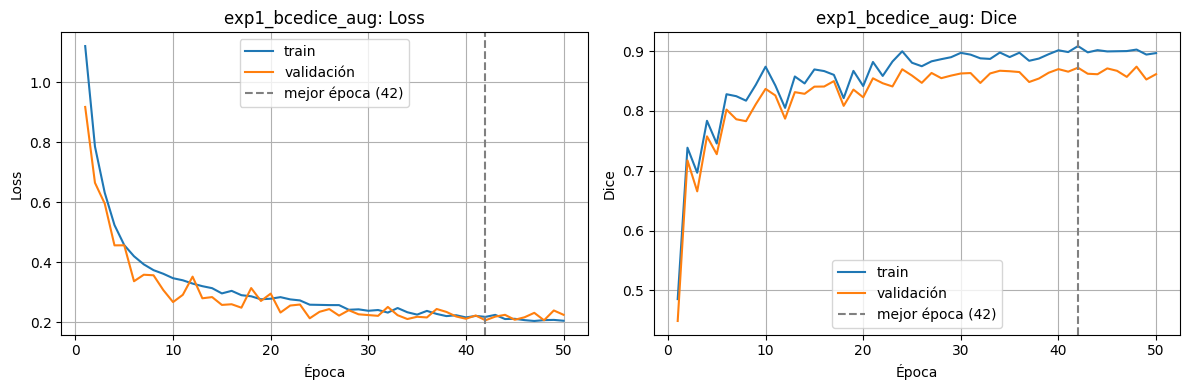

submission_exp1_bcedice_aug.csv generado con 252 filas


,id,encoded_pixels
0,0000.png,124333 1 124772 13 125198 1 125208 28 125644 4...
1,0001.png,69186 9 69677 11 70165 16 70657 16 71148 17 71...
2,0002.png,63466 1 63969 14 64477 18 64986 21 65495 25 66...
3,0003.png,25146 2 25589 4 26032 6 26054 1 26475 7 26493 ...
4,0004.png,24683 1 24685 2 25118 5 25554 6 25989 9 25999 ...
...,...,...
247,0247.png,25443 1 25445 2 25449 1 25966 8 25975 2 26489 ...
248,0248.png,23186 11 23211 3 23636 37 24087 40 24129 12 24...
249,0249.png,93104 2 93543 9 93553 1 93979 19 94424 18 9486...
250,0250.png,75648 2 76067 8 76488 10 76908 13 77330 13 777...


In [ ]:
# Experimento 1
results = globals().get("results", {})
name = "exp1_bcedice_aug"
results[name] = run_experiment(name, PIPE_LOADERS[PIPELINE[name]], **EXPERIMENTS[name])
plot_history(results[name], name)
make_submission(name)

Las curvas del experimento 1 muestran un entrenamiento estable. La pérdida de entrenamiento y la de validación descienden juntas durante todo el entrenamiento, desde valores cercanos a 1.0 en la primera época hasta alrededor de 0.21 al final, sin que la de validación se despegue hacia arriba, lo que indica que el modelo no está sobreajustando. El Dice de validación sube rápido en las primeras épocas, supera 0.80 hacia la época 7 y 0.85 hacia la época 20, y luego sigue mejorando de a poco, con oscilaciones de 0.01 a 0.02 entre épocas consecutivas, mucho menores que las de las corridas previas con tasa de aprendizaje 1e-3. La mejor época es la 42, con un Dice de validación de 0.8722 y un Dice de train de 0.9084. La brecha de alrededor de 0.036 entre ambos es chica y no crece con las épocas. El entrenamiento llegó al máximo de 50 épocas sin que se activara el early stopping.

  Época 001 | loss 1.1659 / 0.9332 | Dice 0.6043 / 0.5833  (train / val)
  Época 002 | loss 0.8598 / 0.7808 | Dice 0.6858 / 0.6842  (train / val)
  Época 003 | loss 0.7302 / 0.7096 | Dice 0.6836 / 0.6600  (train / val)
  Época 004 | loss 0.6348 / 0.5339 | Dice 0.8100 / 0.7739  (train / val)
  Época 005 | loss 0.5676 / 0.4989 | Dice 0.7814 / 0.7780  (train / val)
  Época 006 | loss 0.5303 / 0.4474 | Dice 0.8240 / 0.7936  (train / val)
  Época 007 | loss 0.5069 / 0.4633 | Dice 0.8220 / 0.7926  (train / val)
  Época 008 | loss 0.4932 / 0.4556 | Dice 0.8197 / 0.7914  (train / val)
  Época 009 | loss 0.4730 / 0.4721 | Dice 0.7933 / 0.7790  (train / val)
  Época 010 | loss 0.4522 / 0.4102 | Dice 0.8523 / 0.8179  (train / val)
  Época 011 | loss 0.4473 / 0.3826 | Dice 0.8614 / 0.8339  (train / val)
  Época 012 | loss 0.4310 / 0.4357 | Dice 0.8216 / 0.8010  (train / val)
  Época 013 | loss 0.4234 / 0.3741 | Dice 0.8552 / 0.8373  (train / val)
  Época 014 | loss 0.4227 / 0.3962 | Dice 0.8478 / 

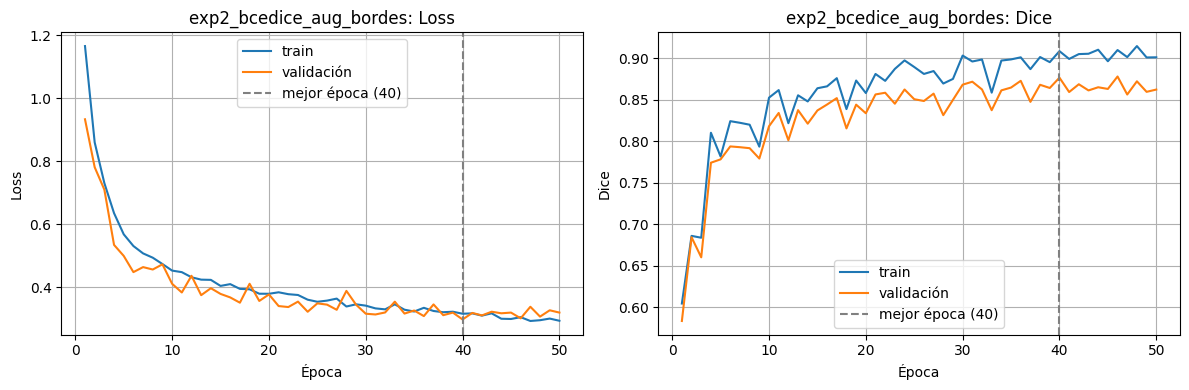

submission_exp2_bcedice_aug_bordes.csv generado con 252 filas


,id,encoded_pixels
0,0000.png,93705 2 94154 8 94603 10 95051 13 95501 14 959...
1,0001.png,100616 8 101106 13 101597 16 102088 17 102580 ...
2,0002.png,63973 7 64481 12 64989 15 65498 18 66007 23 66...
3,0003.png,26938 7 26946 2 26949 1 27378 20 27821 22 2825...
4,0004.png,32027 1 32461 3 32896 5 33331 6 33766 7 34201 ...
...,...,...
247,0247.png,48063 4 48586 9 49111 12 49635 16 50155 24 501...
248,0248.png,98394 1 98843 6 99296 7 99748 9 100200 11 1006...
249,0249.png,88222 1 88225 1 88665 5 89109 5 89553 5 89997 ...
250,0250.png,76490 1 76909 9 77330 11 77751 13 78172 15 785...


In [ ]:
# Experimento 2
results = globals().get("results", {})
name = "exp2_bcedice_aug_bordes"
results[name] = run_experiment(name, PIPE_LOADERS[PIPELINE[name]], **EXPERIMENTS[name])
plot_history(results[name], name)
make_submission(name)

Las curvas del experimento 2 tienen la misma forma general que las del experimento 1, ya que comparten la tasa de aprendizaje, la paciencia y el data augmentation: la pérdida desciende de manera sostenida y el Dice de validación sube rápido en las primeras épocas y luego se estabiliza. Su Dice de validación alcanzó 0.8764 en la mejor época (época 40, con 0.9083 en train), quedando en el mismo rango que los demás experimentos: la diferencia de +0.004 respecto del experimento 1 queda dentro del ruido propio de una sola semilla y 270 imágenes. Una explicación posible es que en ecografía el borde de la lesión es difuso y la anotación manual es ruidosa justamente en esa zona, de modo que dar seis veces más peso a esos píxeles también amplifica el ruido de anotación. La pérdida de este experimento (~0.30) es más alta que la del experimento 1 (~0.21) y no es comparable con ella, porque la ponderación multiplica el peso de los píxeles del contorno, que son los más difíciles de clasificar.

  Época 001 | loss 1.1636 / 1.0027 | Dice 0.5498 / 0.5328  (train / val)
  Época 002 | loss 0.8573 / 0.7422 | Dice 0.7253 / 0.7236  (train / val)
  Época 003 | loss 0.7159 / 0.6523 | Dice 0.7383 / 0.7085  (train / val)
  Época 004 | loss 0.6226 / 0.5199 | Dice 0.8192 / 0.7874  (train / val)
  Época 005 | loss 0.5602 / 0.4869 | Dice 0.7892 / 0.7799  (train / val)
  Época 006 | loss 0.5243 / 0.4628 | Dice 0.7992 / 0.7814  (train / val)
  Época 007 | loss 0.5109 / 0.4645 | Dice 0.8231 / 0.7892  (train / val)
  Época 008 | loss 0.4949 / 0.5392 | Dice 0.7551 / 0.7346  (train / val)
  Época 009 | loss 0.4653 / 0.4315 | Dice 0.8238 / 0.8010  (train / val)
  Época 010 | loss 0.4525 / 0.4066 | Dice 0.8619 / 0.8194  (train / val)
  Época 011 | loss 0.4422 / 0.4287 | Dice 0.8248 / 0.8100  (train / val)
  Época 012 | loss 0.4364 / 0.3888 | Dice 0.8498 / 0.8291  (train / val)
  Época 013 | loss 0.4246 / 0.3671 | Dice 0.8597 / 0.8415  (train / val)
  Época 014 | loss 0.4208 / 0.3738 | Dice 0.8738 / 

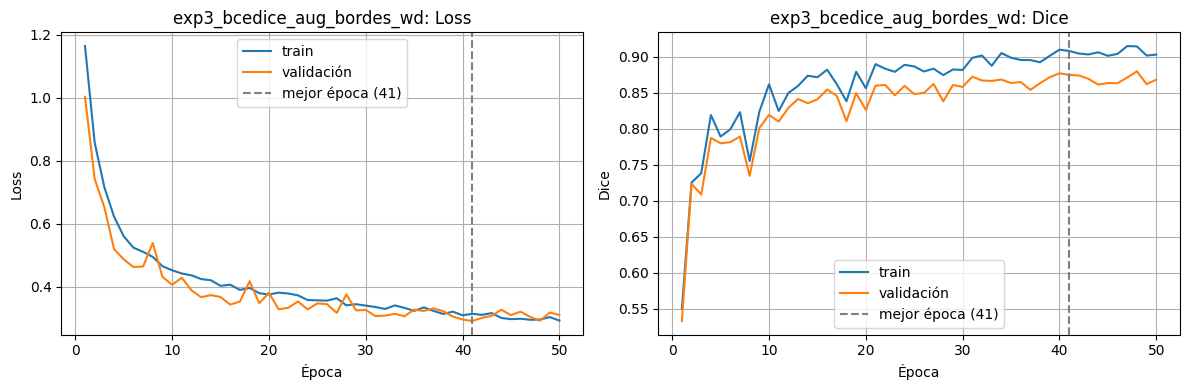

submission_exp3_bcedice_aug_bordes_wd.csv generado con 252 filas


,id,encoded_pixels
0,0000.png,121150 1 121600 1 122050 1 122499 7 122946 11 ...
1,0001.png,100616 7 101105 12 101597 14 102089 15 102580 ...
2,0002.png,62440 9 62947 16 63455 22 63964 28 64473 31 64...
3,0003.png,23811 1 24254 4 24263 1 24696 12 25140 13 2515...
4,0004.png,32462 2 32897 3 33332 5 33768 6 34203 9 34216 ...
...,...,...
247,0247.png,40178 8 40704 11 41230 12 41756 13 42284 12 42...
248,0248.png,18213 3 18665 7 19115 10 19566 12 20018 13 204...
249,0249.png,101519 2 101963 5 101970 3 102407 5 102414 5 1...
250,0250.png,75646 2 76066 9 76487 12 76908 14 77329 16 777...


In [ ]:
# Experimento 3
results = globals().get("results", {})
name = "exp3_bcedice_aug_bordes_wd"
results[name] = run_experiment(name, PIPE_LOADERS[PIPELINE[name]], **EXPERIMENTS[name])
plot_history(results[name], name)
make_submission(name)

Las curvas del experimento 3 son muy similares a las del experimento 2, del que solo difiere en el weight decay de 1e-4, y su Dice de validación alcanzó 0.8750 en la época 41 (con 0.9083 en train y una brecha de 0.033). Con AdamW, un weight decay de 1e-4 es una regularización suave, y la batch normalization y el data augmentation ya regularizan el modelo, por lo que no se observó un efecto claro ni sobre el Dice de validación ni sobre la brecha entre train y validación. Este experimento fue el primero que se envió a Kaggle y obtuvo 0.685 en la tabla pública, muy por debajo de su Dice de validación. Esa diferencia mostró que el modelo resolvía bien los equipos de entrenamiento pero no generalizaba a los del test, y motivó el experimento 4.

  Época 001 | loss 1.2000 / 0.9617 | Dice 0.6413 / 0.6135  (train / val)
  Época 002 | loss 0.8444 / 0.7368 | Dice 0.7712 / 0.7419  (train / val)
  Época 003 | loss 0.6765 / 0.5828 | Dice 0.8088 / 0.7620  (train / val)
  Época 004 | loss 0.5784 / 0.4499 | Dice 0.8349 / 0.8180  (train / val)
  Época 005 | loss 0.5234 / 0.4102 | Dice 0.8391 / 0.8210  (train / val)
  Época 006 | loss 0.4915 / 0.3887 | Dice 0.8575 / 0.8268  (train / val)
  Época 007 | loss 0.4517 / 0.3898 | Dice 0.8589 / 0.8141  (train / val)
  Época 008 | loss 0.4366 / 0.3779 | Dice 0.8569 / 0.8197  (train / val)
  Época 009 | loss 0.4288 / 0.3502 | Dice 0.8728 / 0.8373  (train / val)
  Época 010 | loss 0.4002 / 0.3343 | Dice 0.8790 / 0.8473  (train / val)
  Época 011 | loss 0.3978 / 0.3214 | Dice 0.8758 / 0.8521  (train / val)
  Época 012 | loss 0.3827 / 0.4009 | Dice 0.8247 / 0.8050  (train / val)
  Época 013 | loss 0.3822 / 0.3627 | Dice 0.8665 / 0.8286  (train / val)
  Época 014 | loss 0.3695 / 0.3184 | Dice 0.8871 / 

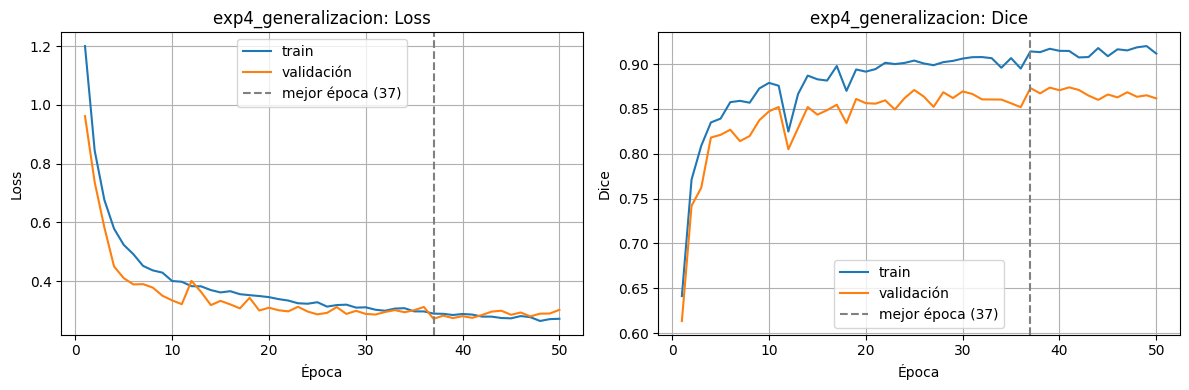

submission_exp4_generalizacion.csv generado con 252 filas


,id,encoded_pixels
0,0000.png,65751 2 65763 2 66197 22 66646 25 67095 28 675...
1,0001.png,84315 2 84361 1 84807 6 84851 7 85299 8 85342 ...
2,0002.png,64486 1 64992 10 65500 13 66009 16 66518 18 67...
3,0003.png,26939 2 27378 11 27808 4 27822 12 27838 3 2825...
4,0004.png,40719 10 41153 15 41587 18 42022 20 42457 22 4...
...,...,...
247,0247.png,22807 4 23332 7 23858 9 24383 11 24909 12 2543...
248,0248.png,86539 3 86993 2 87446 2 87899 2 88352 2 88804 ...
249,0249.png,76442 13 76883 21 77326 24 77767 30 78209 39 7...
250,0250.png,78178 9 78597 15 79018 17 79440 19 79861 21 80...


In [ ]:
# Experimento 4
results = globals().get("results", {})
name = "exp4_generalizacion"
results[name] = run_experiment(name, PIPE_LOADERS[PIPELINE[name]], **EXPERIMENTS[name])
plot_history(results[name], name)
make_submission(name)

Las curvas del experimento 4 muestran un comportamiento distinto en train y en validación a partir de la mitad del entrenamiento. El Dice de validación sube rápido hasta alrededor de 0.84 en la época 10 y llega a 0.86 hacia la época 20, pero a partir de ahí queda estabilizado entre 0.85 y 0.87 hasta el final, mientras que el Dice de train sigue subiendo de forma sostenida hasta alrededor de 0.92. Lo mismo se ve en las pérdidas: la de entrenamiento sigue bajando hasta 0.26–0.28, y la de validación queda plana entre 0.27 y 0.30 desde la época 25. Esto significa que las épocas posteriores mejoran el ajuste a las imágenes de entrenamiento sin trasladarse a pacientes nuevos, y que la brecha entre train y validación (0.041 en la mejor época) crece hacia el final. Por lo tanto no es necesario seguir sumando épocas: el modelo ya alcanzó su techo en validación dentro de las 50 épocas, y entrenar más solo aumentaría el ajuste a los equipos de entrenamiento. La mejor época es la 37, con un Dice de validación de 0.8732 (y 0.9140 en train), y es la que se conserva gracias a que utils.train restaura los pesos de la mejor época. Con los pesos de la última época (50) el Dice habría sido 0.8616.

### 6.4 Comparación de experimentos

La tabla resume, para cada experimento, la configuración que lo distingue, el Dice de validación con los pesos de la mejor época, el Dice de train en esa misma época, la brecha entre ambos, la mejor época, la cantidad de épocas entrenadas y el tiempo de entrenamiento. Sobre la tabla se imprimen los hiperparámetros comunes a todas las corridas.

El gráfico de la izquierda superpone el Dice de validación por época de los cuatro experimentos y marca con un punto la mejor época de cada uno, que es la que se conserva. No se superponen las pérdidas porque la función de pérdida cambia entre el experimento 1 y los demás, y en el experimento 4 el relleno agrega píxeles de fondo fáciles que cambian la escala de la BCE. El gráfico de la derecha compara el Dice de train y el de validación en la mejor época: la altura de las barras de validación permite comparar los experimentos, y la diferencia entre ambas barras mide el sobreajuste.

En todos los casos la pérdida de entrenamiento desciende de forma sostenida, mientras que el Dice de validación avanza con oscilaciones pequeñas de una época a otra, esperables con 270 imágenes de validación. Con una sola semilla, diferencias de Dice menores a 0.01 entre experimentos están dentro del ruido de la validación. En el experimento 4 el Dice de validación no mide la ventaja que se busca, porque la validación proviene de los mismos equipos que el entrenamiento; su aporte está en la generalización a otros equipos, que se reflejó después en el puntaje de Kaggle. Solo los experimentos 3 y 4 se evaluaron en el test de Kaggle, obteniendo 0.685 y 0.746 en la tabla pública.

Los cuatro experimentos alcanzaron un Dice de validación en un rango muy estrecho, entre 0.872 y 0.876: el experimento 1 obtuvo 0.8722 (época 42), el experimento 2 obtuvo 0.8764 (época 40), el experimento 3 obtuvo 0.8750 (época 41) y el experimento 4 obtuvo 0.8732 (época 37). Ni la ponderación de bordes ni el weight decay produjeron mejoras que superen el ruido de la validación. En todos los casos la reducción de la tasa de aprendizaje a 5e-4 dio curvas mucho más estables que las corridas previas con 1e-3. La diferencia decisiva entre los experimentos no apareció en la validación sino en Kaggle, donde el experimento 4 superó al experimento 3 por +0.061 puntos de Dice.

In [ ]:
rows = []
for name, r in results.items():
    best_idx = r["best_epoch"] - 1
    rows.append({"run": name, "aug": r["config"]["augmentation"], "dice_weight": r["config"]["dice_weight"], "edge_w0": r["config"].get("edge_w0", 0.0),
                 "weight_decay": r["config"]["weight_decay"], "dropout": r["config"]["dropout"],
                 "val_dice": r["val_dice"], "train_dice": r["train_dices"][best_idx],
                 "gap_train_val": r["train_dices"][best_idx] - r["val_dices"][best_idx],
                 "mejor_época": r["best_epoch"], "épocas": r["n_epochs"], "tiempo_s": round(r["train_time_sec"])})

summary_df = pd.DataFrame(rows).set_index("run")
print(f"Hardware: {HARDWARE} | seed={SEED} | batch_size={BATCH_SIZE} | lr={LR} | base={BASE} | img={IMG_SIZE}")
summary_df.round(4)

Hardware: GPU CUDA (Tesla T4) | seed=23 | batch_size=16 | lr=0.0005 | base=32 | img=320


,aug,dice_weight,edge_w0,weight_decay,dropout,val_dice,train_dice,gap_train_val,mejor_época,épocas,tiempo_s
run,,,,,,,,,,,
exp1_bcedice_aug,True,1.0,0.0,0.0000,0.0,0.8722,0.9084,0.0362,42,50,4244
exp2_bcedice_aug_bordes,True,1.0,5.0,0.0000,0.0,0.8764,0.9083,0.0319,40,50,4260
exp3_bcedice_aug_bordes_wd,True,1.0,5.0,0.0001,0.0,0.8750,0.9083,0.0333,41,50,4266
exp4_generalizacion,True,1.0,5.0,0.0001,0.0,0.8732,0.9140,0.0408,37,50,4235


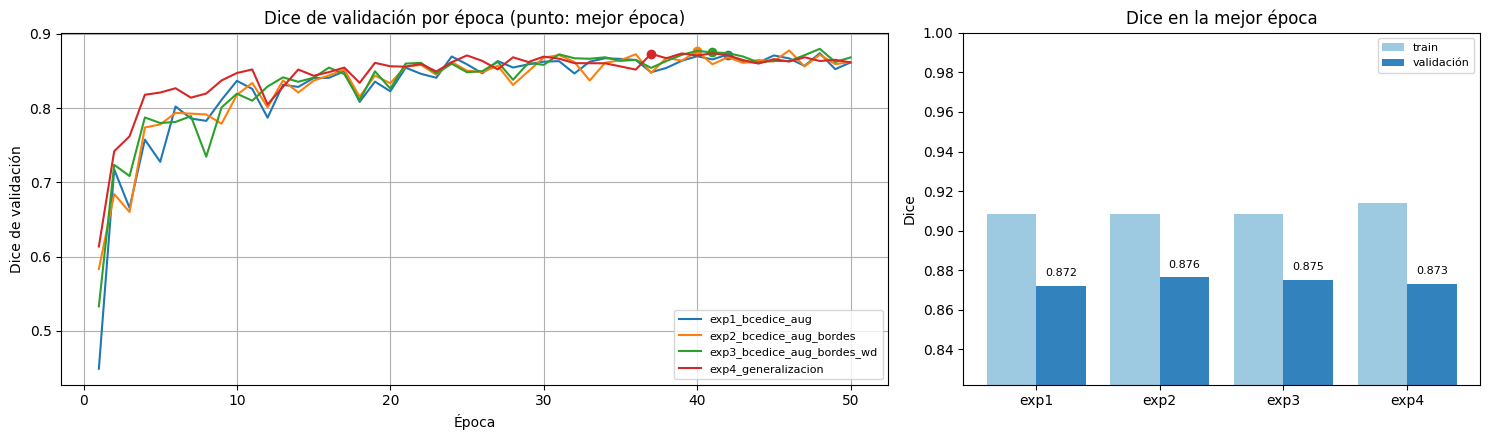

In [ ]:
names = list(results)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
for name in names:
    r = results[name]
    axes[0].plot(range(1, r["n_epochs"] + 1), r["val_dices"], label=name)
    axes[0].plot(r["best_epoch"], r["val_dices"][r["best_epoch"] - 1], "o", color=axes[0].lines[-1].get_color())
axes[0].set(title="Dice de validación por época (punto: mejor época)", xlabel="Época", ylabel="Dice de validación")
axes[0].grid(True)
axes[0].legend(fontsize=8)

pos = np.arange(len(names))
train_best = [results[n]["train_dices"][results[n]["best_epoch"] - 1] for n in names]
val_best = [results[n]["val_dice"] for n in names]
axes[1].bar(pos - 0.2, train_best, 0.4, label="train", color="#9ecae1")
axes[1].bar(pos + 0.2, val_best, 0.4, label="validación", color="#3182bd")
for x, v in zip(pos, val_best):
    axes[1].text(x + 0.2, v + 0.005, f"{v:.3f}", ha="center", fontsize=8)
axes[1].set_xticks(pos, [n.split("_")[0] for n in names])
axes[1].set(title="Dice en la mejor época", ylabel="Dice", ylim=(min(val_best + train_best) - 0.05, 1))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.5 Ensamble de tres particiones

Una vez entrenado el experimento 4, se decidió construir un ensamble a partir de esa configuración, con el mismo objetivo de mejorar la estabilidad del modelo.

Si $p_k(x)$ es la probabilidad que asigna el modelo $k$ al píxel $x$, con su test-time augmentation, la probabilidad del ensamble es

$$\bar p(x) = \frac{1}{K} \sum_{k=1}^{K} p_k(x), \qquad K = 3,$$



In [ ]:
ENSEMBLE_EXP = 4
ENSEMBLE_FOLDS = [0, 1, 2]    # pliegues de validación (≈14 % cada uno); el 0 es la partición principal

ens_name = next(n for n in EXPERIMENTS if n.startswith(f"exp{ENSEMBLE_EXP}_"))
ens_pipe = PIPELINE[ens_name]
ens_ds_train, ens_ds_eval = PIPE_DATA[ens_pipe]["ds_train"], PIPE_DATA[ens_pipe]["ds_eval"]
ensemble = globals().get("ensemble", {})
print(f"Ensamble de {ens_name} (pipeline {ens_pipe}) con los pliegues {ENSEMBLE_FOLDS}")

def train_fold(fold):
    key = (ens_name, fold)
    if key in ensemble:
        print(f"{ens_name} pliegue {fold}: ya entrenado (Dice val {ensemble[key]['val_dice']:.4f})")
        return
    if fold == 0 and ens_name in results:
        ensemble[key] = results[ens_name]
        print(f"{ens_name} pliegue 0: se reutiliza el modelo de la sección 6.3 (Dice val {ensemble[key]['val_dice']:.4f})")
        return
    fold_train_idx, fold_val_idx = split_cases(np.arange(len(df)), fold=fold)
    print(f"{ens_name} pliegue {fold}: train {len(fold_train_idx)} | val {len(fold_val_idx)} imágenes")
    ensemble[key] = run_experiment(f"{ens_name}_fold{fold}", get_loaders(fold_train_idx, fold_val_idx, ens_ds_train, ens_ds_eval), **EXPERIMENTS[ens_name])
    plot_history(ensemble[key], f"{ens_name} pliegue {fold}")

train_fold(ENSEMBLE_FOLDS[0])

Ensamble de exp4_generalizacion (pipeline v2) con los pliegues [0, 1, 2]
exp4_generalizacion pliegue 0: se reutiliza el modelo de la sección 6.3 (Dice val 0.8732)


exp4_generalizacion pliegue 1: train 1605 | val 270 imágenes
  Época 001 | loss 1.1449 / 0.8749 | Dice 0.6825 / 0.6982  (train / val)
  Época 002 | loss 0.8250 / 0.6863 | Dice 0.7187 / 0.7287  (train / val)
  Época 003 | loss 0.6684 / 0.6848 | Dice 0.6580 / 0.6589  (train / val)
  Época 004 | loss 0.5747 / 0.4350 | Dice 0.8220 / 0.8344  (train / val)
  Época 005 | loss 0.5138 / 0.4873 | Dice 0.7648 / 0.7654  (train / val)
  Época 006 | loss 0.4885 / 0.5252 | Dice 0.7066 / 0.7224  (train / val)
  Época 007 | loss 0.4681 / 0.4148 | Dice 0.8066 / 0.8125  (train / val)
  Época 008 | loss 0.4379 / 0.3504 | Dice 0.8480 / 0.8439  (train / val)
  Época 009 | loss 0.4151 / 0.3246 | Dice 0.8571 / 0.8558  (train / val)
  Época 010 | loss 0.4100 / 0.3538 | Dice 0.8394 / 0.8393  (train / val)
  Época 011 | loss 0.3985 / 0.3262 | Dice 0.8660 / 0.8558  (train / val)
  Época 012 | loss 0.3783 / 0.3154 | Dice 0.8571 / 0.8553  (train / val)
  Época 013 | loss 0.3899 / 0.3028 | Dice 0.8765 / 0.8696  (tra

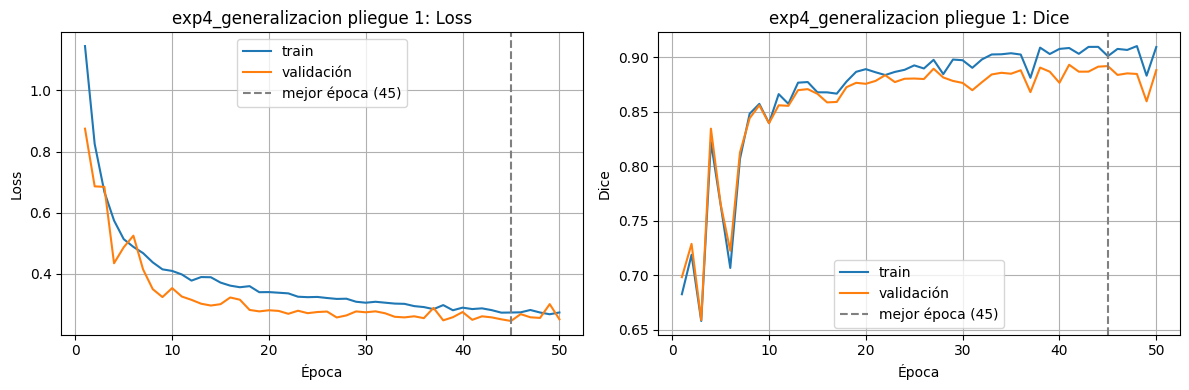

In [ ]:
# Ensamble: segundo pliegue
train_fold(ENSEMBLE_FOLDS[1])

exp4_generalizacion pliegue 2: train 1606 | val 269 imágenes
  Época 001 | loss 1.1519 / 0.9196 | Dice 0.6858 / 0.6411  (train / val)
  Época 002 | loss 0.8098 / 0.7200 | Dice 0.7854 / 0.7576  (train / val)
  Época 003 | loss 0.6542 / 0.5869 | Dice 0.8054 / 0.7788  (train / val)
  Época 004 | loss 0.5562 / 0.5076 | Dice 0.7974 / 0.7729  (train / val)
  Época 005 | loss 0.5044 / 0.4322 | Dice 0.8331 / 0.8151  (train / val)
  Época 006 | loss 0.4560 / 0.4582 | Dice 0.8075 / 0.8008  (train / val)
  Época 007 | loss 0.4469 / 0.3943 | Dice 0.8489 / 0.8249  (train / val)
  Época 008 | loss 0.4180 / 0.3711 | Dice 0.8587 / 0.8390  (train / val)
  Época 009 | loss 0.4096 / 0.3683 | Dice 0.8316 / 0.8385  (train / val)
  Época 010 | loss 0.3970 / 0.3611 | Dice 0.8679 / 0.8389  (train / val)
  Época 011 | loss 0.3936 / 0.3930 | Dice 0.8434 / 0.8134  (train / val)
  Época 012 | loss 0.3813 / 0.3571 | Dice 0.8631 / 0.8361  (train / val)
  Época 013 | loss 0.3779 / 0.4351 | Dice 0.7981 / 0.7986  (tra

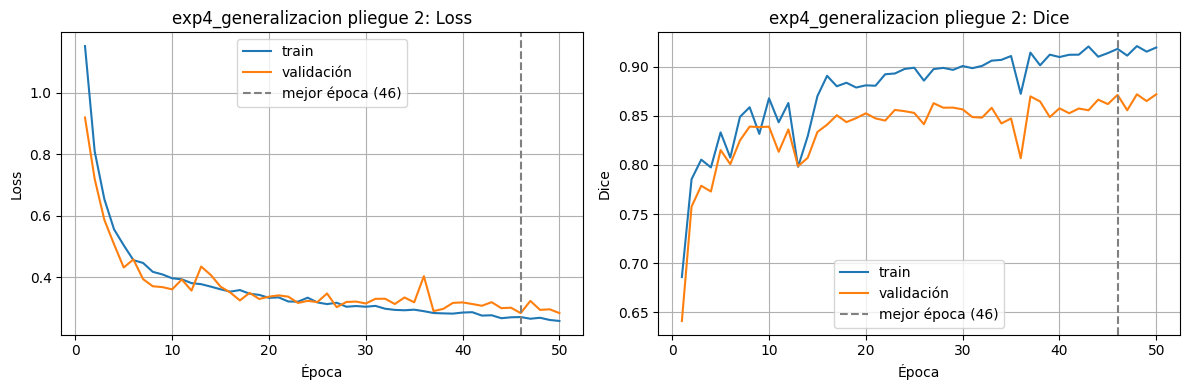

In [ ]:
# Ensamble: tercer pliegue
train_fold(ENSEMBLE_FOLDS[2])

In [ ]:
keys = [(ens_name, f) for f in ENSEMBLE_FOLDS]
faltan = [f for (_, f) in keys if (ens_name, f) not in ensemble]
assert not faltan, f"Faltan entrenar los pliegues {faltan} de {ens_name}"
for (_, f) in keys:
    print(f"pliegue {f}: Dice val {ensemble[(ens_name, f)]['val_dice']:.4f} (mejor época {ensemble[(ens_name, f)]['best_epoch']})")
make_submission_ensemble([ensemble[k]["model"] for k in keys], ens_pipe, f"submission_ensemble_{ens_name}.csv")

pliegue 0: Dice val 0.8732 (mejor época 37)
pliegue 1: Dice val 0.8917 (mejor época 45)
pliegue 2: Dice val 0.8713 (mejor época 46)
submission_ensemble_exp4_generalizacion.csv generado con 252 filas


,id,encoded_pixels
0,0000.png,64863 2 65309 9 65752 1 65758 11 66199 22 6664...
1,0001.png,91282 1 91774 1 92266 1 92758 1 93246 1 93249 ...
2,0002.png,64484 5 64991 11 65499 15 66008 18 66517 21 67...
3,0003.png,29581 1 29585 2 30022 10 30464 15 30489 6 3090...
4,0004.png,40285 8 40717 15 41152 17 41586 20 42021 22 42...
...,...,...
247,0247.png,33323 1 33849 4 34376 3 34902 3 35430 2 35957 ...
248,0248.png,98847 3 99298 6 99750 8 100201 11 100654 11 10...
249,0249.png,76444 7 76884 15 77326 22 77768 27 78211 30 78...
250,0250.png,78178 8 78598 12 79019 14 79440 17 79861 19 80...


## 7. Evaluación del modelo final

El modelo final es el del experimento 4. Los cuatro experimentos alcanzaron un Dice de validación similar, entre 0.85 y 0.88, por lo que la validación no permitía distinguir entre ellos. Con desempeños equivalentes en validación, se eligió el experimento 4 por ser el único diseñado para generalizar a equipos distintos de los de entrenamiento. El resultado en Kaggle, que se vio después, confirmó que la elección fue adecuada: el experimento 4 obtuvo 0.746 en la tabla pública frente a 0.685 del experimento 3.

### 7.1 Desempeño por imagen, equipo, patología y tamaño de lesión

La celda siguiente evalúa el modelo final sobre el conjunto de validación (pacientes no vistos en entrenamiento) aplicando el mismo umbral de 0.5 y filtrado por componente conexa más grande que se usa para Kaggle. Además del Dice por imagen, se calculan la tasa de falsos negativos (fracción de la lesión real no detectada) y de falsos positivos (fracción de la predicción que cae fuera de la lesión), desagregando los resultados por equipo (`device`), patología (`pathology`) y cuartiles de tamaño de lesión (`Q1` a `Q4`).

Dice medio: 0.8746 | mediana: 0.9220 | desvío: 0.1644
Imágenes con Dice < 0.5: 10 de 270 | con Dice = 0: 4
Falsos negativos medios: 0.113 de la lesión | falsos positivos medios: 0.114 de la predicción


,imagenes,dice_medio,dice_mediana,falsos_neg,falsos_pos
device,,,,,
GE Logiq 5 @10-12MHz,118,0.893,0.930,0.108,0.091
GE Logiq 7 @10-14MHz,131,0.882,0.917,0.102,0.119
Toshiba Aplio 300 @12-14 MHz,18,0.686,0.800,0.241,0.244
U-Systems @10-14MHz,3,0.964,0.965,0.038,0.034


,imagenes,dice_medio,dice_mediana,falsos_neg,falsos_pos
pathology,,,,,
benign,181,0.880,0.926,0.097,0.117
malignant,89,0.863,0.915,0.147,0.107


,imagenes,dice_medio,dice_mediana,falsos_neg,falsos_pos
tamaño,,,,,
Q1 (más chicas),68,0.846,0.909,0.095,0.182
Q2,67,0.862,0.922,0.140,0.108
Q3,67,0.893,0.927,0.103,0.088
Q4 (más grandes),68,0.898,0.934,0.116,0.078


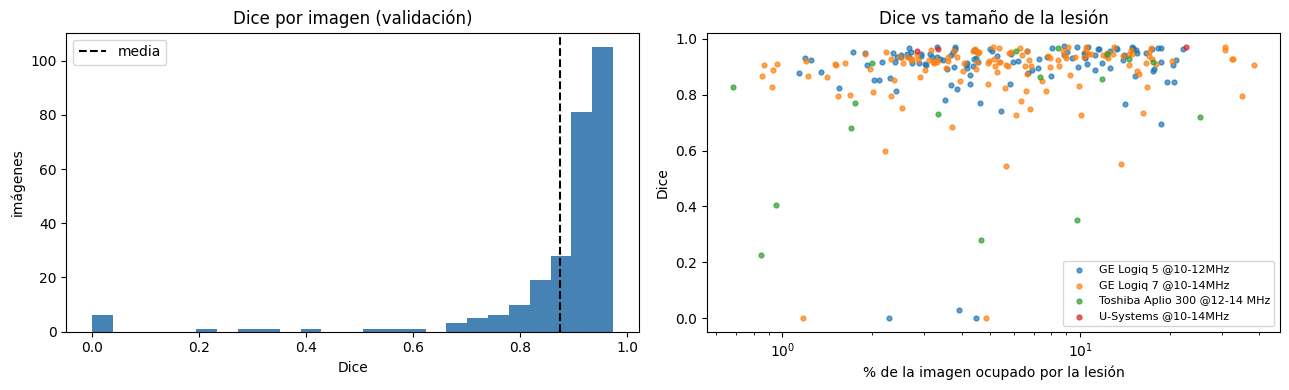

In [ ]:
FINAL_EXP = "exp4_generalizacion"
final_model = results[FINAL_EXP]["model"]
ld_final = PIPE_LOADERS[PIPELINE[FINAL_EXP]]
X_fin, Y_fin = PIPE_DATA[PIPELINE[FINAL_EXP]]["X"], PIPE_DATA[PIPELINE[FINAL_EXP]]["Y"]

@torch.no_grad()
def probs_of(model, loader):
    model.eval()
    return torch.cat([torch.sigmoid(model(x.to(DEVICE))).cpu() for x, _ in loader])[:, 0].numpy()

val_probs = probs_of(final_model, ld_final["val"])
y_val = Y_fin[va_idx, 0].numpy().astype(bool)
pred_val = [mask_from_prob(p).astype(bool) for p in val_probs]

val_dice_img = np.array([2 * (p & y).sum() / max(p.sum() + y.sum(), 1) for p, y in zip(pred_val, y_val)])
fn_frac = np.array([(y & ~p).sum() / max(y.sum(), 1) for p, y in zip(pred_val, y_val)])
fp_frac = np.array([(p & ~y).sum() / max(p.sum(), 1) for p, y in zip(pred_val, y_val)])
val_df = df.iloc[va_idx].assign(dice=val_dice_img, falsos_neg=fn_frac, falsos_pos=fp_frac)
val_df["tamaño"] = pd.qcut(val_df["lesion_frac"], 4, labels=["Q1 (más chicas)", "Q2", "Q3", "Q4 (más grandes)"])

print(f"Dice medio: {val_dice_img.mean():.4f} | mediana: {np.median(val_dice_img):.4f} | desvío: {val_dice_img.std():.4f}")
print(f"Imágenes con Dice < 0.5: {(val_dice_img < 0.5).sum()} de {len(val_dice_img)} | con Dice = 0: {(val_dice_img == 0).sum()}")
print(f"Falsos negativos medios: {fn_frac.mean():.3f} de la lesión | falsos positivos medios: {fp_frac.mean():.3f} de la predicción")

agg = dict(imagenes=("dice", "count"), dice_medio=("dice", "mean"), dice_mediana=("dice", "median"),
           falsos_neg=("falsos_neg", "mean"), falsos_pos=("falsos_pos", "mean"))
for col in ["device", "pathology", "tamaño"]:
    display(val_df.groupby(col, observed=True).agg(**agg).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(val_dice_img, bins=25, color="steelblue")
axes[0].axvline(val_dice_img.mean(), color="k", linestyle="--", label="media")
axes[0].set(title="Dice por imagen (validación)", xlabel="Dice", ylabel="imágenes")
axes[0].legend()
for dev, g in val_df.groupby("device"):
    axes[1].scatter(100 * g["lesion_frac"], g["dice"], s=12, alpha=.7, label=dev)
axes[1].set(title="Dice vs tamaño de la lesión", xlabel="% de la imagen ocupado por la lesión", ylabel="Dice", xscale="log")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 7.2 Segmentaciones correctas e incorrectas

Las tablas de la sección 7.1 muestran que el modelo final alcanza sobre la validación (aplicando el filtrado por componente conexa más grande) un Dice medio de 0.8746 y una mediana de 0.9220, con tasas medias equilibradas de falsos negativos (11.3 %) y falsos positivos (11.4 %). Solo 10 de las 270 imágenes tienen Dice menor a 0.5, y apenas 4 tienen Dice igual a 0. El desglose por cuartiles de tamaño confirma que las lesiones más pequeñas (`Q1`) son las más difíciles, con el menor Dice medio (0.846) y la mayor tasa de falsos positivos (18.2 %), mientras que el desempeño sube de forma monótona con el tamaño de la lesión hasta `Q4` (Dice medio 0.898 y falsos positivos de 7.8 %). Por patología, las lesiones benignas obtienen un Dice levemente superior a las malignas (0.880 frente a 0.863, ya que las malignas presentan contornos más irregulares y mayor tasa de falsos negativos: 14.7 % frente a 9.7 %).

En las figuras siguientes se visualizan los cinco mejores y los cinco peores casos de validación según el Dice, comparando la máscara manual (fila superior) con la predicción final del modelo (fila inferior). Un falso negativo (FN) alto indica que el modelo subsegmentó la lesión, lo que ocurre sobre todo en lesiones pequeñas o de bordes difusos. Un falso positivo (FP) alto indica que el modelo confundió otra región hipoecoica oscura del tejido (como sombras acústicas posteriores) con una lesión; en los 4 casos extremos donde esa región falsa resultó más grande que la lesión real, `keep_largest_component` conservó la componente equivocada y el Dice cayó a 0.00 (FN = 1.00, FP = 1.00).

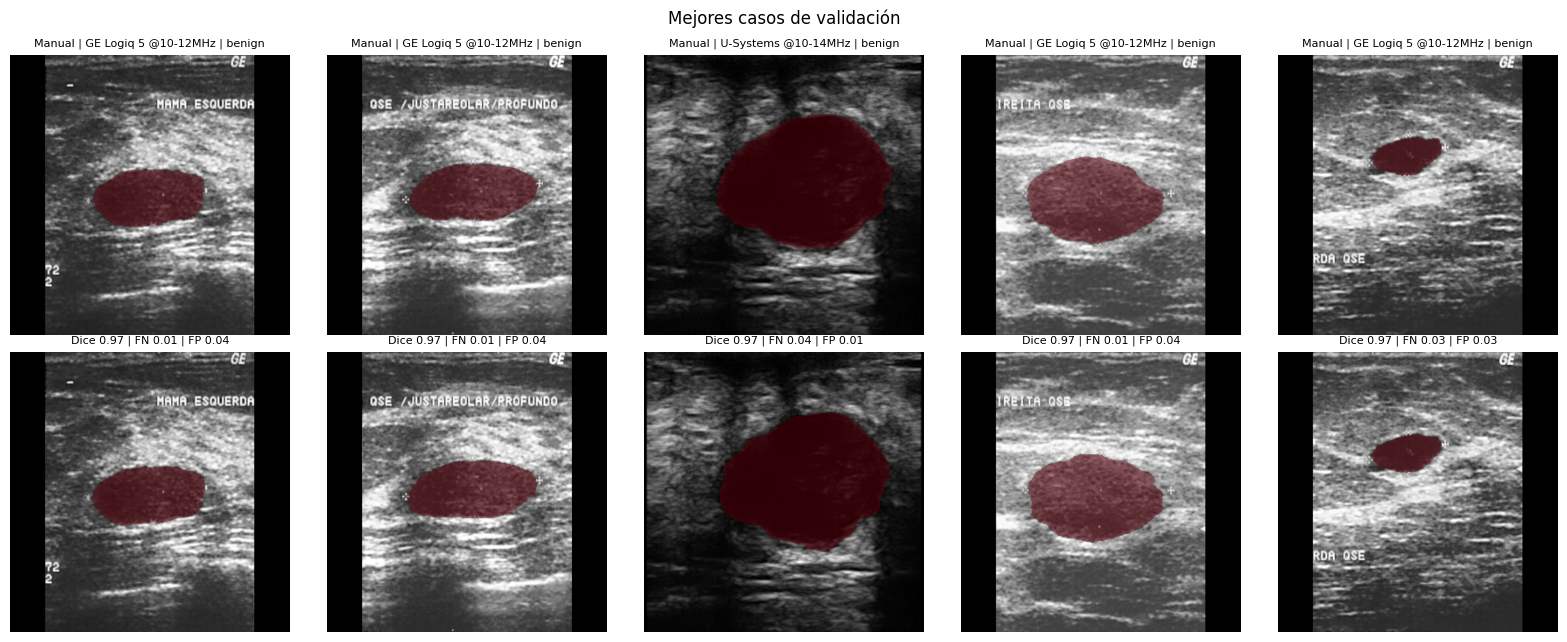

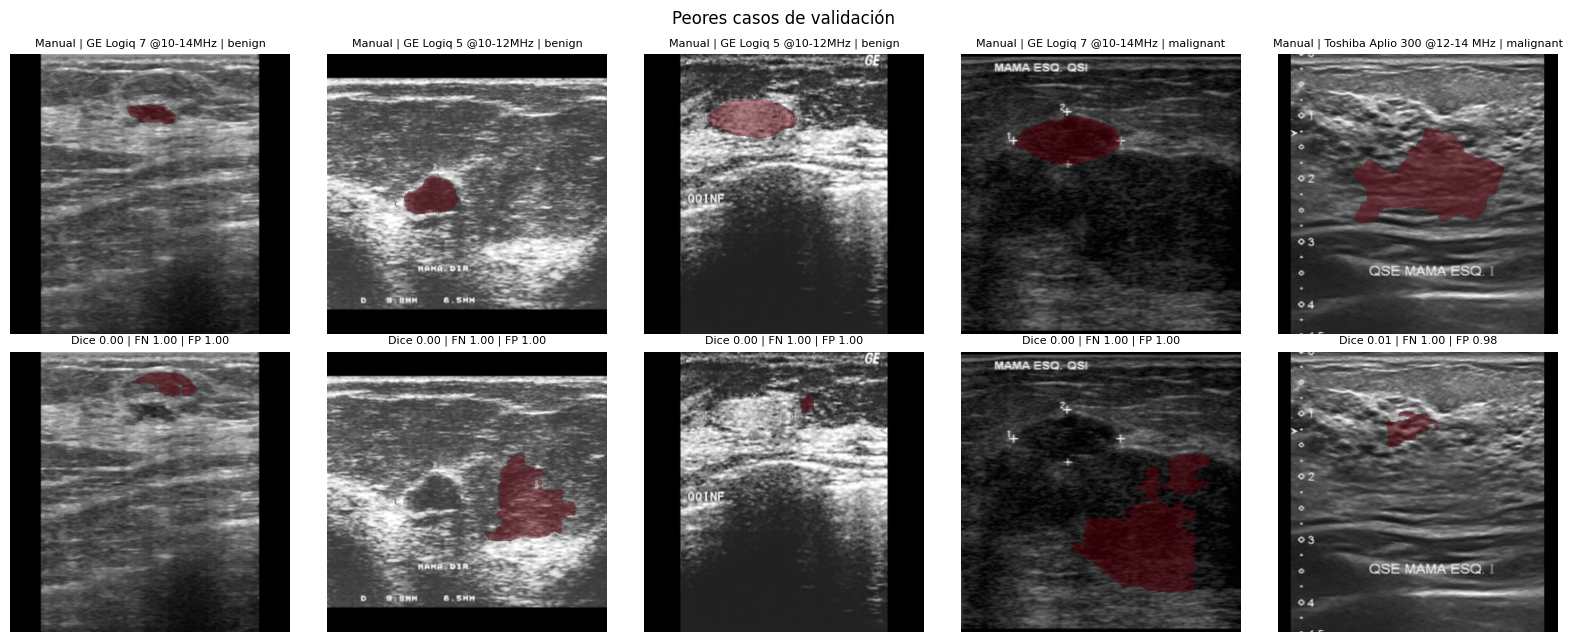

In [ ]:
def show_cases(order, title):
    fig, axes = plt.subplots(2, len(order), figsize=(3.2 * len(order), 6.5), squeeze=False)
    for j, i in enumerate(order):
        g = va_idx[i]
        img = X_fin[g, 0].numpy()
        row = val_df.iloc[i]
        show_overlay(axes[0, j], img, y_val[i], f"Manual | {row['device']} | {row['pathology']}")
        show_overlay(axes[1, j], img, pred_val[i], f"Dice {val_dice_img[i]:.2f} | FN {fn_frac[i]:.2f} | FP {fp_frac[i]:.2f}")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

order = np.argsort(val_dice_img)
show_cases(order[::-1][:5], "Mejores casos de validación")
show_cases(order[:5], "Peores casos de validación")

### 7.3 Efecto del cambio de dominio

El test proviene de otros centros y de otros ecógrafos, y el efecto de ese cambio de dominio se refleja tanto en la diferencia entre validación y Kaggle (de ~0.87 en validación a 0.685 en el experimento 3 y 0.746 en el experimento 4) como en el desglose por equipo dentro de la propia validación (sección 7.1). Mientras que en los dos ecógrafos mayoritarios GE Logiq 5 y GE Logiq 7 (que suman el 91 % del entrenamiento) el modelo alcanza un Dice medio de 0.893 y 0.882 (medianas de 0.930 y 0.917), en Toshiba Aplio 300 (18 imágenes en validación) el Dice medio baja a 0.686 (mediana 0.800), duplicando las tasas de falsos negativos (24.1 %) y falsos positivos (24.4 %). (El equipo U-Systems obtiene 0.964, pero cuenta con solo 3 imágenes en validación).

Este comportamiento en Toshiba anticipa exactamente lo que ocurre en el test de Kaggle: ante ecógrafos poco vistos o nuevos —donde cambian la relación de aspecto, el rango dinámico de grises y la textura del ruido speckle—, las lesiones pequeñas o de bajo contraste rodeadas de sombras acústicas sufren mayor tasa de falsos positivos y subsegmentación. La mejora de +0.061 puntos de Dice en Kaggle del experimento 4 respecto del experimento 3 (y el desempeño de los tres pliegues del ensamble: 0.8732, 0.8917 y 0.8713) confirma que conservar la relación de aspecto (`pad_square`), estandarizar cada imagen por separado y entrenar con variaciones de gamma, desenfoque y speckle reduce de forma efectiva la sensibilidad al cambio de dominio.

## 8. Modelo final

Se guardan los pesos del modelo final (`exp4_generalizacion`) en `unet_final.pt` y se exporta su archivo de predicciones como `submission.csv`, conservando además el envío del ensamble de tres particiones para la selección final de la competencia.

In [ ]:
torch.save(results[FINAL_EXP]["model"].state_dict(), "unet_final.pt")
shutil.copy(f"submission_{FINAL_EXP}.csv", "submission.csv")
print(f"Modelo final: {FINAL_EXP} | submission.csv = submission_{FINAL_EXP}.csv")

Modelo final: exp4_generalizacion | submission.csv = submission_exp4_generalizacion.csv


## 9. Conclusiones

Se implementó desde cero en PyTorch una U-Net fiel a la estructura del paper original, incorporando adaptaciones justificadas para la tarea: convoluciones con padding, batch normalization, 32 filtros base, salida sigmoide con pérdida combinada BCE + Dice, optimizador AdamW y partición por paciente estratificada por equipo (`StratifiedGroupKFold`).

Los cuatro experimentos alcanzaron un Dice de validación muy similar, entre 0.872 y 0.876 (0.8722 en el experimento 1, 0.8764 en el experimento 2, 0.8750 en el experimento 3 y 0.8732 en el experimento 4). Mientras que la ponderación de bordes y el weight decay no produjeron diferencias significativas en validación, reducir la tasa de aprendizaje de 1e-3 a 5e-4 y aumentar la paciencia a 15 épocas fue clave para estabilizar el entrenamiento. Dado que la validación proviene de los mismos equipos que el entrenamiento, fue fundamental diseñar el preprocesamiento del experimento 4 (pipeline v2) pensando en el cambio de ecógrafo: conservar la relación de aspecto, estandarizar por imagen y aplicar augmentation de intensidad permitió pasar de 0.685 (experimento 3) a 0.746 (experimento 4) en la tabla pública de Kaggle. Como paso siguiente se construyó un ensamble de tres particiones sobre esa configuración (que alcanzaron Dices de validación de 0.8732, 0.8917 y 0.8713 en los pliegues 0, 1 y 2) con el objetivo de reducir la varianza y mejorar la generalización.

Adicionalmente, en una prueba para Kaggle se agregó al experimento 4 la transformación `RandomAffine` (con traslación de hasta 5 %, escala entre 0.95 y 1.05 y una leve cizalla) y se obtuvo 0.75985 en la tabla pública. Si bien se podría entrenar esa configuración con todos los datos y ensamblar varias semillas, entendimos que para el desarrollo metodológico del Obligatorio no correspondía guiar la experimentación con los resultados del conjunto de test, por lo que no se avanzó en esa línea.

**Con más tiempo y memoria de GPU, el grupo pasaría las imágenes de 320×320 a 512×512 y el cuello de botella de 512 a 1024 canales, con 64 filtros base en lugar de 32 como en el paper original, para evaluar el efecto de estos cambios que no fue posible probar por el límite de memoria disponible en Colab.**